# Posterior sampling of rupture rates: full workflow

This notebook runs the whole workflow from the raw `cru_A.txt` / `cru_D.txt` files to the summary tables:

1. self-tests of the sampler against exact answers;
2. loading, cleaning and characterising the problem (`preliminaries.py`), with the MFD bins' uncertainty level set by `MFD_UNCERTAINTY`;
3. replicate runs (`gibbs.py`) under the spike-and-slab prior (each rupture switched off, or on with a log-uniform rate below a soft top at its bin's target rate R_j, and the fraction on in each bin estimated) and the Gaussian likelihood, with, by default, every prediction kept above zero (`BAND = 'positive'`, optionally with a soft band, `BAND_SOFT`; or instead within a factor 10 of its target, `BAND = 10`), and optionally a balance term that keeps each data type from being predicted all low or all high (`DOWN_THE_MIDDLE`, off by default), by default an MFD that never rises where its targets do not (`MFD_MONOTONIC`), a soft term on the slip rates summed along cross-sections perpendicular to the plate motion (`SLIP_SUM`, on by default), and optionally a hard constraint on the share of the plate rate the faults take up (`PLATE_RATE`, off by default);
4. convergence checks (R̂ against its noise baseline, effective sample sizes, the hyperparameters, agreement between replicates; `check_convergence.py`) and how well each row block is fitted (`block_fit.py`);
5. the results (exceedance probabilities per rupture, subsection and bin totals; `make_tables.py`), exported as CSV files keyed by the original rupture and row numbers, with representative draws and figures.

**Setup.** Keep this notebook beside the `tools/` folder, which holds the scripts it runs (`cru_common.py`, `preliminaries.py`, `gibbs.py`, `check_convergence.py`, `block_fit.py`, `make_tables.py`, `select_draws.py`, `plot_rate_magnitude.py`, `plot_slip_rates.py`, `plot_paleo_rates.py`, `make_solution.py`, `plate_rate.py`) and the others, for the command line. The two data files (with, if there is one, the model's OpenSHA solution folder, such as `NZSHM22_InversionSolution-211k`, whose rupture set lets the workflow write rates as OpenSHA solutions) and the outputs can live in folders of their own: set `DATA_DIR` (whose files are only read) and `RUN_DIR` (everything the workflow writes: the cleaned problem, the runs, figures and CSV tables) in the configuration cell. By default `DATA_DIR` is `~/inversions/NZSHM22_Matrices-211k/` and `RUN_DIR` a new subfolder of it named after the settings and the start time (`SLIP_SECTIONSauto_MFD_UNCERTAINTYas-given_DOWN_THE_MIDDLE_False_preset_conservative_floor-10_positive_mfdmonotonic_slipsumall_L08.5_<unix time>`); relative paths are taken from this notebook's folder. Within `RUN_DIR`, the cleaned problem and diagnostics stay at the top, the best fit's outputs go into `nnls/` (its rate vectors and figures and, with the model's OpenSHA rupture set, `RUPTURE_SET`, the best fit's rates for OpenSHA, `nnls/rates.csv`), and the runs, tables and figures go into `spikeslab/`, each with a copy of the configuration; to keep two settings (a second floor, say), give the second its own `RUN_DIR`, as the default name does. A different `MFD_UNCERTAINTY` or `SLIP_SECTIONS` changes the cleaned problem, so it too needs its own `RUN_DIR`. Everything the notebook prints (its own messages, the scripts' output, warnings, and any error with its traceback) is also written to a log in that subfolder, `workflow_log_<date>-<time>.txt`, a new one each time the configuration cell runs; in Jupyter the log also records when each cell started and how long it took, and which figures were shown. Each step is a script, and each also keeps what it prints in a report next to its outputs: `prelim_summary.txt` (cleaning, at the top of `RUN_DIR`), `nnls/solution_report.txt` (the best fit's rates for OpenSHA), and in `spikeslab/` `<run>_log.txt` (each run), `convergence_report.txt`, `block_fit_report.txt`, `tables_report.txt`, `select_report.txt` (the representative draws), `solution_report.txt` (the posterior mean's rates for OpenSHA) and each figure's table in `.txt`. Requirements: numpy, scipy, pandas, matplotlib, and a C compiler (`xcode-select --install` on macOS) for the Gibbs kernel. Edit the configuration cell, then run all cells in order. `PRESET = 'conservative'`, the default, uses production settings; `'very_conservative'` (16 chains, 3 replicates; spike-and-slab's lengths are set for 2e5–5e5 ruptures: on an M2's four performance cores 4 h 14 min at 211,000 ruptures for the reference run, and an estimated 11–12 hours at 5e5), aims at 10,000 effective draws per rupture, so that exceedance probabilities near 0.02 carry under 10% Monte Carlo error. `'quick'` takes minutes. See `REPORT.md` for the reasoning behind every choice.

In [ ]:
# Configuration: edit this cell, then run all cells in order.
import os, sys, json, time, subprocess, csv
import numpy as np

DATA_DIR = '~/inversions/NZSHM22_Matrices-211k/'   # folder with the input data files, which are only read (RUN_DIR
                                           # below is by default a new subfolder of it); relative paths are taken from
                                           # this notebook's folder (the scripts are in its tools/)
A_FILE, D_FILE = 'cru_A.txt', 'cru_D.txt'  # input file names, inside DATA_DIR
BLOCKS = None                              # row groups by original row numbers, e.g. 'S=0-387,MFD=695-713,P=714-753'.
                                           # None detects the slip-rate rows (the leading rows, up to the first zero-forcing
                                           # penalty row) and the magnitude-bin rows; any group named is checked against them
SLIP_BLOCK, BIN_BLOCK = 'S', 'MFD'         # blocks used for subsection and magnitude-bin summaries
SLIP_SECTIONS = 'auto'                     # slip-rate measurements: 'auto' (default): each run of subsections holding
                                           # copies of one fault section's slip rate is one measurement (its k rows are
                                           # divided by sqrt(k)); rows unlike their neighbours (a geodetic model, say) are
                                           # unchanged; 'none': every subsection its own measurement (the inputs as given;
                                           # a sensitivity test, in its own RUN_DIR); or a file in DATA_DIR of
                                           # 'original_row section' lines (e.g. the rupture set's subsection-to-section map)
MFD_UNCERTAINTY = 'as-given'               # the MFD bins' uncertainty level, applied at cleaning; their bin-to-bin
                                           # shape (the power, 0.25 in the NZSHM22 inputs) stays as cru_A/cru_D give it.
                                           # 'as-given' (default): the inputs' uncertainties (10% at M7.0-7.1, their design
                                           # value), each bin its own measurement; 'two-measurements': the bins are a
                                           # projection of two measurements, the rate of M>=5 and the b-value, so together
                                           # they count as two measurements, not one per bin: every bin's uncertainty is
                                           # multiplied by sqrt(bins / 2) (3 for 18 bins: 30% at M7.0-7.1); a number: the
                                           # M7.0-7.1 bin's relative uncertainty, one sd (0.1 reproduces the inputs). A
                                           # different setting changes the cleaned problem, so it needs its own RUN_DIR
DOWN_THE_MIDDLE = False                    # a second term in the misfit (gibbs.py --down-the-middle): each data type's
                                           # relative shortfall s = sum of predictions / sum of targets - 1 (slip-rate
                                           # sections, MFD bins, paleo rows, in units of each measurement's uncertainty)
                                           # costs A s^2. True: the same A for every type, so predicting a type all at 0, or
                                           # summing to twice its targets, is equally bad for each; A is the largest such
                                           # weight that keeps every type at or below one extra measurement (30-63% of each
                                           # type's zero-model misfit for the NZSHM22 inputs). 'zero-model': each type's
                                           # own A, its zero-model misfit, so s = -1 or +1 costs a type what the zero model
                                           # costs it in chi2 (1.6-3.4 times True's weight). False (default): the Gaussian
                                           # misfit alone (with BAND, which holds every type near its targets). The sampler
                                           # only: the best fit ignores it. Each setting needs its own
                                           # RUN_DIR (REPORT.md, 'Balance between over- and underprediction')
BAND = 'positive'                          # a hard constraint on every slip-rate (each subsection's row), MFD-bin and
                                           # paleo prediction. 'positive' (default; gibbs.py --positive): each kept
                                           # above zero, at least one rupture on in each row. A number (10, say;
                                           # gibbs.py --band): each kept within that factor of its target. None:
                                           # neither. The sampler
                                           # only; a start outside it is first moved inside (about 1.5 minutes at
                                           # 211,000 ruptures for the band; at once for 'positive'). A different setting
                                           # needs its own RUN_DIR
BAND_SOFT = None                           # a soft version of the band, with BAND = 'positive' (gibbs.py --log-band):
                                           # a Gaussian penalty on each such prediction's log ratio to its target, with
                                           # BAND_SOFT decades at 1 sd (1: within an order of magnitude at 1 sd, two at
                                           # 2 sd; 2: within two orders at 1 sd), each slip-rate subsection 1/k of its
                                           # section's. None (default): not imposed. The sampler only, recorded apart
                                           # from chi2; about 2.4 times the time per sweep at 211,000 ruptures, and about
                                           # half the effective draws. A different setting needs its own RUN_DIR
MFD_MONOTONIC = True                       # True (default): in every model, wherever a magnitude bin's target is not above the
                                           # next lower bin's, its total rate is not above that bin's either (with the
                                           # NZSHM22 targets, every pair from M6.9-7.0 up; where a target rises, the rise
                                           # capped 0.89 sd above the target difference), a hard constraint (gibbs.py --mfd-monotonic), with
                                           # BAND or alone. False: not imposed.
                                           # The sampler only. A different setting needs its own RUN_DIR
PLATE_RATE = None                          # a hard constraint on the share of the Pacific-Australia plate rate that
                                           # the South Island's crustal faults take up (gibbs.py --plate-rate, with the
                                           # rupture set, RUPTURE_SET): (0.4, 0.8), say, keeps it between 0.4 and 0.8 in
                                           # every model, in each of 8 strips about 76 km wide between the cross-sections
                                           # where the Alpine Fault goes offshore and through the Needles-Wairarapa
                                           # step-over in Cook Strait (each fault's slip vector on the local plate motion,
                                           # added up across it; plate_rate.py). None (default): not imposed. The sampler
                                           # only; the start must be inside (at 211,000 ruptures the best fit is:
                                           # 0.58-0.73). A different setting needs its own RUN_DIR
SLIP_SUM = 'all'                           # a soft term in the misfit (gibbs.py --slip-sum, with the rupture set,
                                           # RUPTURE_SET): along every cross-section perpendicular to the plate motion,
                                           # the model's slip rates added up against the targets added up, within the
                                           # uncertainty of that sum (copies of one fault section's slip rate
                                           # correlated), each subsection counting once in all, weighted by SLIP_SUM_L0
                                           # (plate_rate.py). 'all' (default): over all of New Zealand; 'between': only
                                           # between the same two edges; None: not added. Recorded apart from chi2 (the
                                           # fit check). The sampler only. A different setting needs its own RUN_DIR
SLIP_SUM_L0 = 8.5                          # SLIP_SUM's weight: the length along the plate motion (km) that counts as one
                                           # measurement. 8.5 (default): the strips' width (the mean subsection length),
                                           # so each strip's sum is one extra observation (72 between the edges, 166 over
                                           # New Zealand). 120: the target sums' decorrelation length between the edges,
                                           # about 5 measurements between them; a shorter length weighs it more
RUPTURE_SET = 'auto'                       # the OpenSHA rupture set of these inputs, for writing rates as an OpenSHA
                                           # solution's rates.csv (in nnls/ and spikeslab/; make_solution.py checks that
                                           # both describe the same ruptures). 'auto' (default): the one OpenSHA solution
                                           # folder in DATA_DIR (e.g. NZSHM22_InversionSolution-211k), if there is one; or
                                           # that folder's name, or its ruptures/ folder, in DATA_DIR; None: no rates.csv
PRESET = 'conservative'                    # 'conservative' (default) for production runs; 'very_conservative' for the
                                           # most precise results (several times longer); 'quick' to try the workflow
FLOOR = -10                                # log10 rate below which rates are negligible (-10 by default, 1e-10):
                                           # spike-and-slab's slab floor (the lower end of its 'on' range), and the cutoff
                                           # below which rates count as equal in the convergence checks and the
                                           # preliminaries' collective-scale check (REPORT.md, "Floors and cutoff")
REPRESENTATIVES = 100                      # representative draws for hazard (100 by default): each run keeps 1,000 whole
                                           # draws (gibbs.py --keep-draws) and select_draws.py picks this many weighted
                                           # representatives, written as columns rep_01... of rate_vectors.csv; 0 turns
                                           # both off
THREADS = 4                                # the M2's performance cores
RUN_SELFTESTS = False                      # exact tests of spike-and-slab and the balance term (gibbs.py --selftest
                                           # current), about half a minute; worth doing once on each machine
RUN_NAME = (f'SLIP_SECTIONS{SLIP_SECTIONS}_MFD_UNCERTAINTY{MFD_UNCERTAINTY}_DOWN_THE_MIDDLE_{DOWN_THE_MIDDLE}'
            f'_preset_{PRESET}_floor{FLOOR}' + ('_positive' if BAND == 'positive' else f'_band{BAND:g}' if BAND else '')
            + (f'_bandsoft{BAND_SOFT:g}' if BAND_SOFT else '')
            + ('_mfdmonotonic' if MFD_MONOTONIC else '')
            + (f'_plate{PLATE_RATE[0]:g}-{PLATE_RATE[1]:g}' if PLATE_RATE else '')
            + (f'_slipsum{SLIP_SUM}_L0{SLIP_SUM_L0:g}' if SLIP_SUM else '')
            + f'_{int(time.time())}')                # the default RUN_DIR's name
RUN_DIR = os.path.join(DATA_DIR, RUN_NAME)  # folder for everything the workflow writes (created if
                                           # missing): by default a new subfolder of DATA_DIR named after the settings
                                           # and the start time, so that each run has its own

# Run lengths. A minority of ruptures switch on and off slowly, so the runs are long; hyper_every sets how often (in
# sweeps) the fraction on in each bin is updated (cheap). Swap moves, exact exchanges of rate between near-duplicate
# ruptures in the same bin, run once per recorded draw (every thin sweeps).
PRESETS = {
    'quick':             dict(chains=4, sweeps=2400, burn=400, thin=8, hyper_every=1, replicates=2),
    # the conservative and very conservative lengths are set for 2e5-5e5 ruptures (October 2026): mixing per sweep
    # barely changed from 2e4 to 2e5, the chains settle within about 30 sweeps of the best fit, and draws 32 sweeps
    # apart are nearly independent (TESTING.md, 'Run lengths, timing and storage')
    'conservative':      dict(chains=8, sweeps=30000, burn=3000, thin=32, hyper_every=1, replicates=2),
    # at least 10,000 effective draws for 95% of ruptures, so exceedance probabilities near 0.02 carry under 10%
    # Monte Carlo error. On an M2's 4 performance cores, about 4.6 h for the replicates at 211,000 ruptures and
    # 11-12 h at 5e5 (estimates)
    'very_conservative': dict(chains=16, sweeps=120000, burn=10000, thin=32, hyper_every=1, replicates=3),
}
if not (isinstance(DOWN_THE_MIDDLE, bool) or DOWN_THE_MIDDLE == 'zero-model'):
    raise ValueError(f"DOWN_THE_MIDDLE = {DOWN_THE_MIDDLE!r}: use True (the balance term), 'zero-model' (its per-type "
                     'weights) or False (the Gaussian misfit alone)')
if not isinstance(MFD_MONOTONIC, bool):
    raise ValueError(f'MFD_MONOTONIC = {MFD_MONOTONIC!r}: use True or False')
if PLATE_RATE is not None and not (isinstance(PLATE_RATE, (tuple, list)) and len(PLATE_RATE) == 2
                                   and all(isinstance(v, (int, float)) and not isinstance(v, bool) for v in PLATE_RATE)
                                   and 0 <= PLATE_RATE[0] < PLATE_RATE[1]):
    raise ValueError(f'PLATE_RATE = {PLATE_RATE!r}: use None (not imposed) or (low, high), shares of the plate rate with '
                     '0 <= low < high: (0.4, 0.8), say')
if SLIP_SUM not in (None, 'all', 'between'):
    raise ValueError(f"SLIP_SUM = {SLIP_SUM!r}: use None (not added), 'all' (all of New Zealand) or 'between' (only "
                     'between the Alpine and Cook Strait edges)')
if isinstance(SLIP_SUM_L0, bool) or not isinstance(SLIP_SUM_L0, (int, float)) or not SLIP_SUM_L0 > 0:
    raise ValueError(f'SLIP_SUM_L0 = {SLIP_SUM_L0!r}: give a length in km above 0 (120 by default)')
if BAND is not None and BAND != 'positive' and (isinstance(BAND, bool) or not isinstance(BAND, (int, float)) or not BAND > 1):
    raise ValueError(f"BAND = {BAND!r}: use None (no band), a factor above 1 (10: an order of magnitude either way) or "
                     "'positive' (every prediction above zero)")
if BAND_SOFT is not None and (isinstance(BAND_SOFT, bool) or not isinstance(BAND_SOFT, (int, float)) or not BAND_SOFT > 0
                              or BAND != 'positive'):
    raise ValueError(f"BAND_SOFT = {BAND_SOFT!r}: use None (not imposed) or a width in decades above 0 (1: an order of "
                     "magnitude at 1 sd), with BAND = 'positive' (a prediction of zero is infinitely penalized)")
if PRESET not in ('quick', 'conservative', 'very_conservative'):
    raise ValueError(f"PRESET = {PRESET!r}: use 'quick', 'conservative' (default) or 'very_conservative'")
if isinstance(FLOOR, bool) or not isinstance(FLOOR, (int, float)) or not -16 < FLOOR < 0:
    raise ValueError(f'FLOOR = {FLOOR!r}: give log10 of the slab floor, a negative number (-10 by default)')
if isinstance(REPRESENTATIVES, bool) or not isinstance(REPRESENTATIVES, int) or REPRESENTATIVES < 0:
    raise ValueError(f'REPRESENTATIVES = {REPRESENTATIVES!r}: give a number of draws, 0 or more (100 by default)')
if isinstance(THREADS, bool) or not isinstance(THREADS, int) or THREADS < 1:
    raise ValueError(f'THREADS = {THREADS!r}: give a number of threads, 1 or more')
P = dict(PRESETS[PRESET])
if not (MFD_UNCERTAINTY in ('as-given', 'two-measurements') or (isinstance(MFD_UNCERTAINTY, (int, float))
                                                                   and not isinstance(MFD_UNCERTAINTY, bool) and 0 < MFD_UNCERTAINTY <= 2)):
    raise ValueError(f"MFD_UNCERTAINTY = {MFD_UNCERTAINTY!r}: use 'as-given', 'two-measurements' or the M7.0-7.1 bin's "
                     'relative uncertainty as a fraction (0.3 for 30%)')
if '_NOTEBOOK_DIR' not in globals():       # this notebook's folder, remembered so this cell can be re-run after chdir
    _NOTEBOOK_DIR = os.path.abspath('.')
CODE_DIR = os.path.join(_NOTEBOOK_DIR, 'tools')   # the scripts, in tools/ beside this notebook
_resolve = lambda p: os.path.normpath(os.path.join(_NOTEBOOK_DIR, os.path.expanduser(str(p))))
DATA_DIR, RUN_DIR = _resolve(DATA_DIR), _resolve(RUN_DIR)
for _f in ('gibbs.py', 'cru_common.py', 'preliminaries.py', 'block_fit.py', 'select_draws.py',
           'plot_rate_magnitude.py', 'plot_slip_rates.py', 'plot_paleo_rates.py', 'check_convergence.py', 'make_tables.py',
           'make_solution.py', 'plot_slip_sections.py', 'plate_rate.py'):
    if not os.path.exists(os.path.join(CODE_DIR, _f)):
        raise FileNotFoundError(f'{_f} is not in tools/ beside this notebook ({CODE_DIR})')
for _f in (A_FILE, D_FILE) + (() if SLIP_SECTIONS in ('auto', 'none') else (SLIP_SECTIONS,)):
    if not os.path.exists(os.path.join(DATA_DIR, _f)):
        raise FileNotFoundError(f'{_f} is not in DATA_DIR ({DATA_DIR})')
os.makedirs(RUN_DIR, exist_ok=True)
os.chdir(RUN_DIR)                          # every output lands in RUN_DIR
sys.path.insert(0, CODE_DIR)
from cru_common import start_log, log_only # from here on, everything printed is also written to a log in RESULTS
RESULTS = 'spikeslab'                      # this run's subfolder of RUN_DIR: its results and log
LOG_FILE = start_log(os.path.join(RUN_DIR, RESULTS,   # the log goes with the results
                                  time.strftime('workflow_log_%Y%m%d-%H%M%S.txt')),
                     header=f"cru_workflow log, started {time.strftime('%Y-%m-%d %H:%M:%S')}")
print('code:', CODE_DIR)
print('data:', DATA_DIR)
print('runs:', RUN_DIR)
print('log: ', LOG_FILE)
from cru_common import find_rupture_set
RUPTURE_DIR = (find_rupture_set(DATA_DIR) if RUPTURE_SET == 'auto'          # the OpenSHA rupture set, or None
               else find_rupture_set(os.path.join(DATA_DIR, RUPTURE_SET), search=False) if RUPTURE_SET else None)
if RUPTURE_SET not in (None, 'auto') and RUPTURE_DIR is None:
    raise FileNotFoundError(f'RUPTURE_SET = {RUPTURE_SET!r}: no OpenSHA rupture set there (indices.csv, or ruptures/indices.csv)')
if (PLATE_RATE or SLIP_SUM) and not RUPTURE_DIR:
    raise FileNotFoundError(f'{"PLATE_RATE" if PLATE_RATE else "SLIP_SUM"} needs the model\'s OpenSHA rupture set '
                            '(RUPTURE_SET), for the faults\' traces, rakes and dips; none found')
print('rupture set:', RUPTURE_DIR or 'none (RUPTURE_SET): no rates are written for OpenSHA')


def rupture_dir():
    """The OpenSHA rupture set the solutions are written for, looked for when they are written, so that a solution
    folder that appears in DATA_DIR during the run still serves: RUPTURE_DIR, or, with RUPTURE_SET = 'auto' and none
    found at the start, the rupture set of the one solution folder in DATA_DIR (None if there is none, or several)."""
    if RUPTURE_DIR or RUPTURE_SET != 'auto':
        return RUPTURE_DIR
    try:
        return find_rupture_set(DATA_DIR)
    except ValueError:                            # several solution folders: name one with RUPTURE_SET
        return None


def ref_args():
    """--reference for a fit figure: the model's own OpenSHA solution's rates (its solution/rates.csv), looked for when
    the figure is drawn, so that a solution whose inversion finishes during the run is still marked: beside the rupture
    set, or, with RUPTURE_SET = 'auto' and none found at the start, in the one solution folder in DATA_DIR that has them."""
    if RUPTURE_SET is None:
        return []
    if RUPTURE_DIR:
        found = [os.path.join(os.path.dirname(RUPTURE_DIR), 'solution', 'rates.csv')]
    else:
        found = [os.path.join(DATA_DIR, d, 'solution', 'rates.csv') for d in sorted(os.listdir(DATA_DIR))]
    found = [f for f in found if os.path.isfile(f)]
    return ['--reference', found[0]] if len(found) == 1 else []


print('reference solution (looked for again when each fit figure is drawn):', (ref_args() or [None, 'none yet'])[1])
print(f'settings: {P}')

code: /Users/rollins/Library/CloudStorage/ProtonDrive-c.rollins@gns.cri.nz-folder/Inversions/Material/cru_workflow/tools
data: /Users/rollins/inversions/NZSHM22_Matrices-211k
runs: /Users/rollins/inversions/NZSHM22_Matrices-211k/SLIP_SECTIONSauto_MFD_UNCERTAINTYas-given_DOWN_THE_MIDDLE_False_preset_conservative_floor-10_positive_mfdmonotonic_rise0.89_slipsumall_L08.5_1793659113
log:  /Users/rollins/inversions/NZSHM22_Matrices-211k/SLIP_SECTIONSauto_MFD_UNCERTAINTYas-given_DOWN_THE_MIDDLE_False_preset_conservative_floor-10_positive_mfdmonotonic_rise0.89_slipsumall_L08.5_1793659113/spikeslab/workflow_log_20261103-113833.txt
rupture set: /Users/rollins/inversions/NZSHM22_Matrices-211k/NZSHM22_InversionSolution-211k/ruptures
reference solution (looked for again when each fit figure is drawn): /Users/rollins/inversions/NZSHM22_Matrices-211k/NZSHM22_InversionSolution-211k/solution/rates.csv
settings: {'chains': 8, 'sweeps': 30000, 'burn': 3000, 'thin': 32, 'hyper_every': 1, 'replicates': 2}


In [2]:
def sh(*args):
    """Run one of the workflow scripts with this Python, streaming its output; stop on failure."""
    if str(args[0]).endswith('.py') and not os.path.isabs(str(args[0])):
        args = (os.path.join(CODE_DIR, args[0]),) + tuple(args[1:])      # scripts live in CODE_DIR
    cmd = [sys.executable] + [str(a) for a in args]
    print('$', ' '.join(cmd[1:]), flush=True)
    p = subprocess.Popen(cmd, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True, bufsize=1)
    for line in p.stdout:
        print(line, end='', flush=True)
    if p.wait() != 0:
        raise RuntimeError('command failed: ' + ' '.join(cmd[1:]))


def show(path):
    """Display a figure inline in Jupyter; elsewhere, say where it is."""
    try:
        from IPython.display import Image, display
        display(Image(filename=path))
        log_only(f'figure: {path}')
    except ImportError:
        print('figure:', path)


CONFIG = dict(preset=PRESET, code_dir=CODE_DIR, data_dir=DATA_DIR, run_dir=RUN_DIR, settings=P, floor=FLOOR,
              representatives=REPRESENTATIVES, a_file=A_FILE, d_file=D_FILE, blocks=BLOCKS, slip_sections=SLIP_SECTIONS,
              mfd_uncertainty=MFD_UNCERTAINTY, down_the_middle=DOWN_THE_MIDDLE, band=BAND, band_soft=BAND_SOFT, mfd_monotonic=MFD_MONOTONIC, plate_rate=PLATE_RATE, slip_sum=SLIP_SUM, slip_sum_l0=SLIP_SUM_L0, rupture_set=RUPTURE_SET, rupture_dir=RUPTURE_DIR, reference=(ref_args() or [None, None])[1],
              slip_block=SLIP_BLOCK, bin_block=BIN_BLOCK, threads=THREADS, run_selftests=RUN_SELFTESTS,
              log_file=LOG_FILE, started=time.strftime('%Y-%m-%d %H:%M'))
json.dump(CONFIG, open('workflow_config.json', 'w'), indent=1)
log_only('configuration: ' + json.dumps(CONFIG, default=str))


def results_dir():
    """This run's subfolder of RUN_DIR (RESULTS: spikeslab/): created if needed,
    with a copy of this run's configuration."""
    import shutil
    os.makedirs(RESULTS, exist_ok=True)
    if os.path.exists('workflow_config.json'):
        shutil.copy('workflow_config.json', os.path.join(RESULTS, 'workflow_config.json'))
    return RESULTS

## 1. Self-tests

The Gibbs sampler is checked against exact answers for what the default uses (`gibbs.py --selftest current`): per-rupture lower box edges (the slab floor), the soft top at each bin's target, the spike-and-slab prior, the balance term (`DOWN_THE_MIDDLE`) and swap moves between near-duplicate ruptures, each on both backends. Every line should end in `PASSED`. After any change to the sampler, run the full suite from a terminal (`python tools/gibbs.py --selftest`), which adds deep-tail truncated normals, two- and three-rate problems under flat and exponential priors, transfer moves, the retired hierarchical prior, and the priors that are now `gibbs.py` options only (the square-root slab, the linear and halfway priors).

In [3]:
if RUN_SELFTESTS:
    sh('gibbs.py', '--selftest', 'current')

## 2. Load, clean and characterise

The penalty rows (entries 1e20; 14 in the corrected 2e4 inputs) are removed from G and d together with the parameters they apply to (405), then all-zero rows and columns are removed. The output reports the scales, the spectrum, the resolution, near-duplicate columns and the best nonnegative fit, whose fit to the data is drawn at the end of the notebook, as the posterior's is: slip rates, rates by magnitude (the MFD) and paleo rates, from the best fit's rate vectors. All of the best fit's outputs go into `nnls/` in `RUN_DIR`: its rate vectors (`nnls_vectors.npz`), the three figures (`fig_slip_rates_nnls.png`, `fig_rate_magnitude_nnls.png` and `fig_paleo_rates_nnls.png`, each with its table in `.txt`), its rates as a table with the rows of `rate_vectors.csv`, one per rupture of the inputs (`nnls_vectors.csv`: columns `rupture`, `penalised` and `best_fit`, removed ruptures 0), and, if `DATA_DIR` holds the model's OpenSHA solution folder (`RUPTURE_SET = 'auto'`, the default, finds it: `NZSHM22_InversionSolution-211k`, say; a name picks one), the best fit's rates as an OpenSHA solution's `rates.csv` (`nnls/rates.csv`, written by `make_solution.py`, with its report in `nnls/solution_report.txt`; written at the end of the notebook, as the posterior mean's are). With the model's OpenSHA solution folder in `DATA_DIR`, that solution's own predictions (its `solution/rates.csv`) are marked too, as black squares (open on the slip-rate and paleo figures), on every fit figure (looked for when each is drawn, so a solution whose inversion finishes during the run still counts), with its χ² and a `reference` column in each figure's table. Its rates on ruptures that cleaning removes are left out of those predictions, and the tables say how much (at 211,000 ruptures, 0.14% of its total rate). Before writing the rates, `make_solution.py` checks that the rupture set describes the same ruptures, every kept rupture's fault sections against its slip-rate rows and its magnitude against its bin, and stops if any differ. Cleaning also finds the row groups automatically. The slip-rate rows are the leading rows, up to the first zero-forcing penalty row (right-hand side 0, entries only on penalised ruptures), so a slip-rate row with zero slip does not end them. The magnitude-bin rows are the rows with one constant coefficient whose supports split the ruptures into disjoint groups. Groups that `BLOCKS` does not name are labelled `SLIP_BLOCK` and `BIN_BLOCK`; any group it does name must agree with the detection, or cleaning stops. Cleaning then counts each fault section's slip rate once (`SLIP_SECTIONS = 'auto'`): the inputs copy a section's slip rate, with its uncertainty, to each of its k subsections, so each run of such copies (identical targets, and identical coefficients for the ruptures they share) has its rows divided by √k. Rows unlike their neighbours, as in a geodetic slip-rate model, are unchanged; `'none'` keeps every subsection as its own measurement (a sensitivity test, in its own `RUN_DIR`), and a file of `original_row section` lines sets the sections explicitly. Cleaning reports the fit check: the χ² a draw should have if the uncertainties are right. Cleaning also checks that the slip-rate rows are plausible, printing a short profile (it stops on clear mislabelling and warns about anything suspicious, such as ruptures that appear in no slip-rate row), and checks the bin rows again on the saved problem (the per-bin priors and the bin targets rely on them). What it prints is also kept in `prelim_summary.txt`. The best fit takes about 25 s at 211,000 ruptures, where the whole of cleaning takes about a minute, and the chains start from it (with `BAND`, moved inside the band first by the first run, about 1.5 minutes at 211,000 ruptures, and kept at the top of `RUN_DIR` as `cru_clean_band10_start.npz` for the later runs). The next cell prints the cleaned problem's size and fit check, and warns if `RUN_DIR` holds earlier results made on a problem cleaned otherwise.

**MFD uncertainty** (`MFD_UNCERTAINTY`, `'as-given'` by default). The magnitude bins are not independent observations: they are a projection of two, the rate of M≥5 earthquakes and the b-value, whose own uncertainties the logic tree explores through alternative inputs. The inputs give the bins relative uncertainties of 10% at M7.0–7.1, growing as R_j^−0.25 towards the rarer bins: both are design values chosen where the inputs are built, the 10% a holdover of the UCERF3 practice of weighting data types, where the slip-rate and paleo rows carry their measured uncertainties. `'as-given'` keeps them, each bin its own measurement; counted that way the 18 bins pin their total rate to ±2.8% and their slope to ±0.024 in b. `'two-measurements'` multiplies every bin's uncertainty by √(bins / 2), 3 for 18 bins, so that together they carry the information of the two measurements they come from, as each slip-rate section's copies count once: 30% at M7.0–7.1 (29–46% across the bins), and ±8.3% on the total and ±0.07 on the slope. A number sets the M7.0–7.1 bin's relative uncertainty, the other bins following (0.1 reproduces the inputs). The bin-to-bin shape always stays as the inputs give it, the bins' targets are unchanged, and the soft top's width, the bins' relative uncertainty, follows. Cleaning prints the inputs' uncertainties, the multiplier and what the bins then say about the MFD as a whole; the fit check still counts one measurement per bin. The data cannot set this level, since the bins' misfit is almost all the model's freedom; in quick runs `'two-measurements'` let the slip-rate and paleo rows raise the bins a median 8% above their targets (2% as given) and the total rate by 5%, with the other products within Monte Carlo noise (REPORT.md, "MFD uncertainty").

$ /Users/rollins/Library/CloudStorage/ProtonDrive-c.rollins@gns.cri.nz-folder/Inversions/Material/cru_workflow/tools/preliminaries.py --A /Users/rollins/inversions/NZSHM22_Matrices-211k/cru_A.txt --d /Users/rollins/inversions/NZSHM22_Matrices-211k/cru_D.txt --out cru_clean.npz --bins-block MFD --slip-block S --diag-floor=-10 --slip-sections auto --mfd-uncertainty as-given
== raw: G 8928 x 211042, nnz 9396480; d (8928,); min entry 35.83, max 1e+20
== cleaning step 1: 16 penalty rows contain entries > 1e+10 (values [1.e+20]; original rows [8829, 8830, 8831, 8832, 8833, 8834, 8835, 8836, 8837, 8838, 8839, 8840, 8841, 8842, 8843, 8844]); they apply to 6203 parameters.
   removing those rows from G and d and those parameters from G: 8912 x 204839
== cleaning step 1b: 301 rows after the slip-rate rows have a target of 0 and a single entry left (values [10000.]; original rows 3649-7140): soft zero-forcing penalties on 301 parameters that no penalty row covers
   forcing those parameters to ze

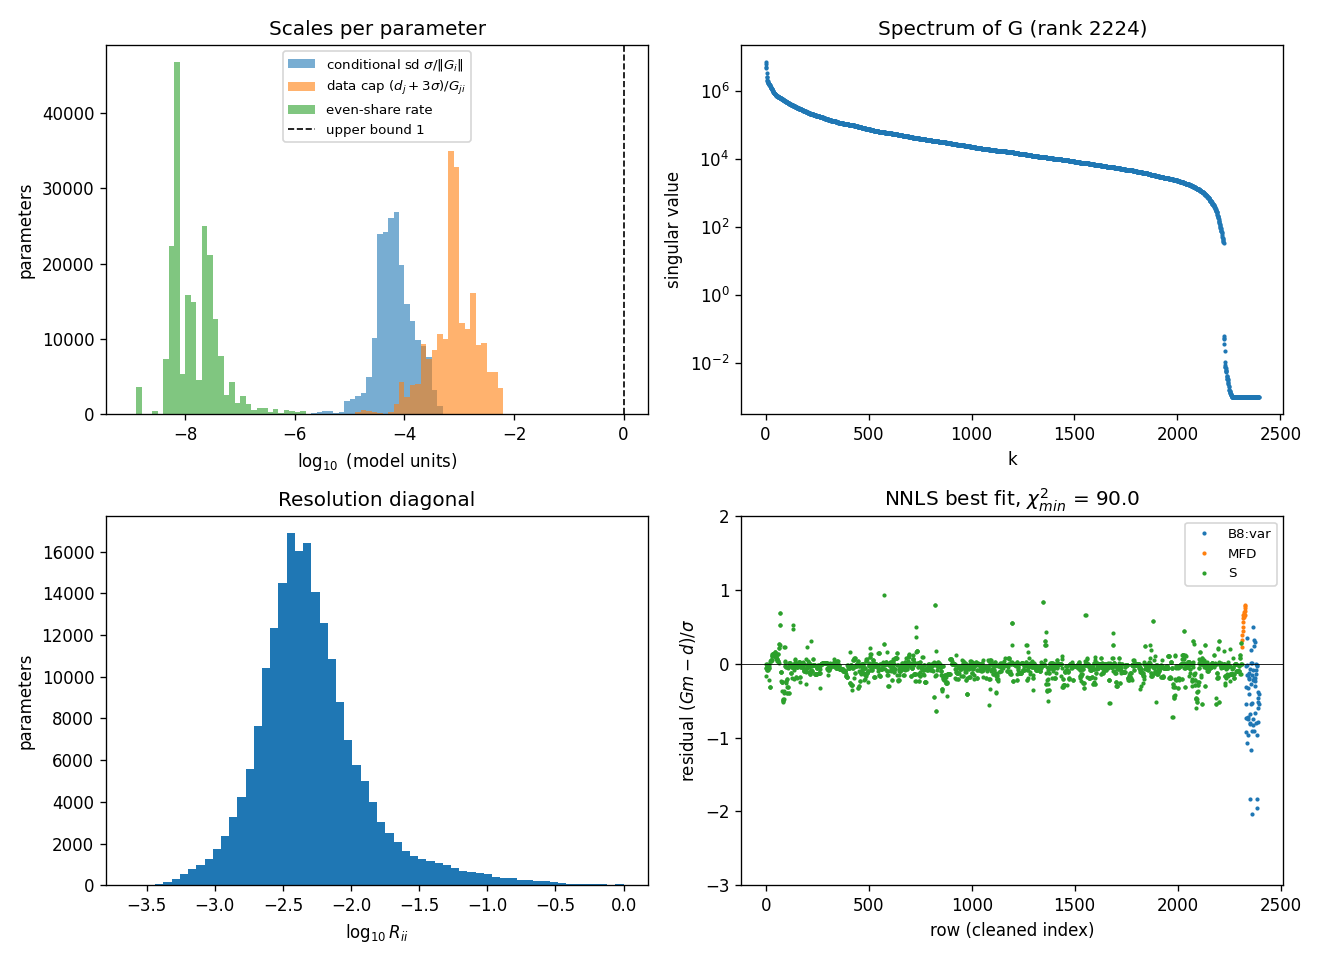

In [4]:
args = ['preliminaries.py', '--A', os.path.join(DATA_DIR, A_FILE), '--d', os.path.join(DATA_DIR, D_FILE), '--out', 'cru_clean.npz',
        '--bins-block', BIN_BLOCK, '--slip-block', SLIP_BLOCK, f'--diag-floor={FLOOR}',
        '--slip-sections', SLIP_SECTIONS if SLIP_SECTIONS in ('auto', 'none') else os.path.join(DATA_DIR, SLIP_SECTIONS),
        '--mfd-uncertainty', MFD_UNCERTAINTY]
if BLOCKS:
    args += ['--blocks', BLOCKS]
_CLEANED_BEFORE = None
if os.path.exists('cru_clean.npz'):                # the settings of a problem cleaned here before, to compare below
    from cru_common import load_problem
    _p = load_problem('cru_clean.npz')
    _CLEANED_BEFORE = (_p['slip_sections'], _p['mfd_uncertainty'])
    del _p
sh(*args)
show('prelim.png')
for _d in ('.', 'nnls'):                           # an earlier cleaning's best-fit figures and rates would not match this
    for _f in (os.listdir(_d) if os.path.isdir(_d) else []):     # problem ('.': the layout before nnls/)
        if (_f.startswith('fig_') and '_nnls.' in _f) or (_d == 'nnls' and _f in ('rates.csv', 'solution_report.txt')):
            os.remove(os.path.join(_d, _f))
for _f in ('rates.csv', 'modules.json', 'sub_seismo_on_fault_mfds.csv'):   # the layout before nnls/rates.csv
    if os.path.exists(os.path.join('nnls', 'solution', _f)):
        os.remove(os.path.join('nnls', 'solution', _f))
for _d in ('nnls/solution', 'nnls'):              # folders left empty
    if os.path.isdir(_d) and not os.listdir(_d):
        os.rmdir(_d)

In [5]:
from cru_common import load_problem
_p = load_problem('cru_clean.npz')                 # the cleaned problem, as the runs will read it
_before = globals().get('_CLEANED_BEFORE')         # set by the cleaning cell: the settings of a problem cleaned here before
if _before is not None and _before != (_p['slip_sections'], _p['mfd_uncertainty']):
    _other = [k_ for k_, f_ in (('spikeslab', 'main_rep0.npz'),) if os.path.exists(os.path.join(k_, f_))]
    if _other:
        print(f'WARNING: RUN_DIR held a problem cleaned with SLIP_SECTIONS {_before[0]!r} and MFD_UNCERTAINTY '
              f"{_before[1]!r}; the results in {', '.join(k_ + '/' for k_ in _other)} were made on it, not on this one. "
              'Give each setting its own RUN_DIR.')
FIT = _p['chi2_expect']                            # the fit check: chi2 of a model that matches the truth
print(f"cleaned problem: {_p['G'].shape[0]} rows x {_p['G'].shape[1]} ruptures; slip-rate sections {_p['slip_sections']!r}; "
      f"MFD uncertainty {_p['mfd_uncertainty']!r}" + (f"; fit check: a draw's chi2 should be near {FIT[0]:.0f} +- {FIT[1]:.0f} "
                                                       'if the uncertainties are right' if FIT is not None else ''))
del _p

cleaned problem: 2395 rows x 204538 ruptures; slip-rate sections 'auto'; MFD uncertainty 'as-given'; fit check: a draw's chi2 should be near 590 +- 34 if the uncertainties are right


## 3. Default runs

**The prior (spike-and-slab):** each rupture is either off, with a rate of exactly 0, or on, with a log-uniform rate from 10^`FLOOR` (1e-10 by default, below the scale at which all ruptures together become invisible to the data) up to a top at its bin's target rate R_j. The top is soft: no rupture can carry more than its bin's true total, which the bin row gives as R_j with its own uncertainty, so the range ends at R_j with a Gaussian shoulder of that width in log rate (0.04–0.06 decades for the 2e4 inputs). Hard tops, at R_j or at F × R_j, are `gibbs.py` options (`--prior spikeslab:-10:hard` or `spikeslab:-10:F`); one at 10 × R_j left the misfits unchanged. The fraction switched on in each bin is estimated (Beta(1, 1) prior), so the data, not a floor or a depth, decide how many ruptures are active, and the prior puts no pressure on the bin totals. In quick tests on the corrected inputs, with one measurement per slip-rate section and the balance term's common weight, without the band (at a slab floor of 1e-10), χ² is 140 ± 12 against the fit check's 126 ± 16, the bin totals sit a median 2% above their targets, and about 45 ruptures carry 90% of the rate; the products barely depend on the slab floor. A minority of ruptures switch on and off slowly, so its runs are long; section 4 also checks the fractions on.

The likelihood is Gaussian, exp(−χ²/2) with the stated uncertainties, for every prior. With `BAND = 10` every prediction must also lie within a factor 10 of its target, from d/10 to 10 d: each subsection's slip-rate row, each MFD bin and each paleo row. It is a hard constraint, a prior that is 0 outside the band, so each update draws only from the rates that keep every row inside it; the chains start from the best fit moved inside the band by a penalized least-squares fit, made once per problem and kept beside it for later runs. The band is stricter than the data where a target is weak (a section whose target is under about one uncertainty would otherwise accept a prediction of 0), so χ² sits below the fit check's range, and it switches on events on faults that share few ruptures (see REPORT.md, "The band"). `BAND = None` leaves it out, and `BAND = 'positive'`, the default, puts a gentler constraint in its place: every prediction only has to be above zero, so at least one rupture is on in each subsection's row, each MFD bin and each paleo row, with no other limit ("Positivity" in REPORT.md). With positivity, `BAND_SOFT` (off by default, `None`) adds a soft version of the band: a Gaussian penalty on each prediction's log ratio to its target, `BAND_SOFT` decades at 1 sd (1: within an order of magnitude at 1 sd, two at 2 sd; 2: within two orders at 1 sd). It acts on the rows with weak targets, where the data would accept predictions near zero, and is kept exactly by a Metropolis step in the sampler, at about 2.4 times the time per sweep and half the effective draws ("A soft band" in REPORT.md). Independently of `BAND`, `MFD_MONOTONIC = True` (the default; `False` turns it off) keeps every model's MFD from rising wherever the targets do not: no bin's total rate above the next lower bin's, from M6.9–7.0 up with the NZSHM22 targets. Where a target rises (only from M6.8–6.9 to M6.9–7.0), the rise is capped instead: the upper bin's total is at most ρ times the lower's, with ρ set at the targets so that the cap sits 0.89 sd above the target difference, as far as the other pairs' walls sit above theirs (the median); ρ = 1.427 for M6.8–6.9, against a target ratio of 1.28 ("A monotonic MFD" in REPORT.md). Two more options need the model's rupture set (`RUPTURE_SET`) and work along cross-sections perpendicular to the plate motion, between two edges: where the Alpine Fault goes offshore, and the Needles–Wairarapa step-over in Cook Strait. `PLATE_RATE = (0.4, 0.8)` (off by default, `None`) keeps, in every model, the share of the Pacific–Australia plate rate that the crustal faults between the edges take up between 0.4 and 0.8: in each of eight strips about 76 km wide, each fault's slip vector projected on the local plate motion, added up across the strip and divided by the local plate rate ("The plate rate" in REPORT.md). `SLIP_SUM = 'all'` (the default; `'between'` for the region between the edges only, `None` to leave it out) adds a soft term to the misfit: along every cross-section, the model's slip rates added up should match the targets added up, within that sum's uncertainty, with each subsection counting once in all; it is weighted so that `SLIP_SUM_L0` of the plate boundary counts as one measurement: 8.5 km by default, the strips' width, so each strip's sum is one extra observation (120 km, the target sums' decorrelation length between the edges, would make it about five there), and it is recorded apart from χ² ("Summed slip rates" in REPORT.md). Both are built by `plate_rate.py`.

With `DOWN_THE_MIDDLE = 'zero-model'` (off by default, `False`) the misfit gains a balance term: each data type's relative shortfall, s = sum of predictions / sum of targets − 1 (the slip-rate sections, the MFD bins and the paleo rows, in units of each measurement's uncertainty), costs A s², with each type's own A, its zero-model misfit, so a type predicted all at 0, or summing to twice its targets, pays in the balance term what the zero model costs it in χ². With `DOWN_THE_MIDDLE = True` one A serves every type instead, the largest common weight that keeps every type at or below one extra measurement: 30–63% of each type's zero-model misfit for the NZSHM22 inputs, so `'zero-model'` weighs 1.6–3.4 times as much. Each run's log gives A and each type's shortfall; the χ² of the fit check and the figures are over the data alone. In quick tests the common weight cut the posterior's mean shortfall in the slip rates by about a fifth and in the paleo rates by a third (2e4) to two-fifths (211,000 ruptures), the bins rising 1–4%, and the per-type weights (the "proposed weight") about halved the mean shortfalls in the slip and paleo rates, the bins rising up to 6% at 211,000 ruptures (REPORT.md, "Balance between over- and underprediction"). Each replicate is an independent `gibbs.py` run with its own seed, started from the best fit, with exact swap moves between near-duplicate ruptures (pairs in the same bin whose columns have cosine above 0.99, one pass per recorded draw). In quick runs at 211,000 ruptures the swap moves cost no measurable time and gave the ruptures that are often on about three times the effective draws, without moving any result (REPORT.md, "Swap moves"). The other priors tried are `gibbs.py` options, for the command line (REPORT.md): the square-root slab (`--slab sqrt`), which fits the data as the default does and so shows what depends on how the lower end of the rates is treated (at 211,000 ruptures the subsections' event rates do, coming out a median 0.62 of the default's); θ = 1 (`--prior binbox-theta:1:0`, the alternative until October 2026, which fitted no better and from about 2e5 ruptures cannot cross its boxes); and the linear, halfway and per-bin-box priors, which push the bin totals up.

In [7]:
def gibbs_run(out, seed=1):
    """One gibbs.py run of spike-and-slab with this preset's run lengths, from the best fit, with swap moves."""
    args = ['gibbs.py', '--problem', 'cru_clean.npz', '--prior', f'spikeslab:{FLOOR}:soft',
            '--chains', P['chains'], '--sweeps', P['sweeps'], '--burn', P['burn'], '--thin', P['thin'],
            '--threads', THREADS, '--seed', seed, '--init', 'nnls', '--out', os.path.join(results_dir(), out)]
    args += [f'--diag-floor={FLOOR}', '--slip-block', SLIP_BLOCK, '--bins-block', BIN_BLOCK, '--no-samples']
    if REPRESENTATIVES > 0:
        args += ['--keep-draws', 1000]                  # whole draws kept for the representatives (a fixed number)
    args += ['--swap-cos', 0.99, '--hyper-every', P['hyper_every']]   # swap moves between near-duplicate ruptures
    if DOWN_THE_MIDDLE:
        args += ['--down-the-middle']                   # the balance term in the misfit
        if DOWN_THE_MIDDLE == 'zero-model':
            args += ['zero-model']                      # each type's own weight, its zero-model misfit
    if BAND == 'positive':
        args += ['--positive']                          # every prediction above zero
        if BAND_SOFT:
            args += ['--log-band', BAND_SOFT]           # and each within BAND_SOFT decades of its target at 1 sd
    elif BAND:
        args += ['--band', BAND]                        # every prediction within a factor BAND of its target
    if MFD_MONOTONIC:
        args += ['--mfd-monotonic']                     # no bin's total above its lower neighbour's where the target isn't;
                                                        # where it rises, the rise capped (gibbs.py's default, 0.89 sd)
    if PLATE_RATE:                                      # each South Island strip's share of the plate rate within limits
        args += ['--plate-rate', f'{PLATE_RATE[0]:g},{PLATE_RATE[1]:g}']
    if SLIP_SUM:                                        # the summed slip rates along each cross-section, a soft term
        args += ['--slip-sum', SLIP_SUM, '--slip-sum-l0', SLIP_SUM_L0]
    if PLATE_RATE or SLIP_SUM:
        args += ['--rupture-set', RUPTURE_DIR]          # the faults' geometry, the ruptures' sections and slips
    sh(*args)
    return os.path.join(RESULTS, out)                   # runs live in RUN_DIR/spikeslab/


t0 = time.time()
MAIN = [gibbs_run(f'main_rep{r}', seed=101 + r) for r in range(P['replicates'])]
RUNS = MAIN
print(f'runs finished in {(time.time() - t0) / 60:.1f} min')

$ /Users/rollins/Library/CloudStorage/ProtonDrive-c.rollins@gns.cri.nz-folder/Inversions/Material/cru_workflow/tools/gibbs.py --problem cru_clean.npz --prior spikeslab:-10:soft --chains 8 --sweeps 30000 --burn 3000 --thin 32 --threads 4 --seed 101 --init nnls --out spikeslab/main_rep0 --diag-floor=-10 --slip-block S --bins-block MFD --no-samples --keep-draws 1000 --swap-cos 0.99 --hyper-every 1 --positive --mfd-monotonic --mfd-rise-sd 0.89 --slip-sum all --slip-sum-l0 8.5 --rupture-set /Users/rollins/inversions/NZSHM22_Matrices-211k/NZSHM22_InversionSolution-211k/ruptures
summed slip rates: along each cross-section, the model's slip rates added up against the targets added up, a soft term in the likelihood beside the data (recorded apart from chi2); 166 strips over all of New Zealand (45 SW of the edges, 72 between them, 49 NE of them), 8.5 km wide (the subsections' mean trace length, 8.5 km); L0 = 8.5 km, so the term counts as 72.0 measurements over the 612 km between the edges, each 

## 4. Convergence checks

For each run: χ² and the total rate (effective sample sizes), and per-rupture log rates (worst R̂, effective sample sizes). The noise baseline is the worst R̂ expected over this many rates if every draw were independent, so rates above it are mixing slowly. For spike-and-slab runs, the number of ruptures on per draw and the fraction on in each bin are checked too. In the log-rate diagnostics, rates below 10^`FLOOR` (1e-10 by default, the same setting as spike-and-slab's slab floor) count as equal for every prior. Below that scale no rate, nor all of them together, can move any prediction by more than a small fraction of its uncertainty; without the clip, spike-and-slab's exact zeros would inflate R̂ with differences no prediction can see. The runs store no draws, so the per-rupture R̂ and effective draws come from the running summaries each run writes (`<run>_stream.npz`): split R̂ is exact, and effective draws are estimated from batch means. `PASS` means the targets in TESTING.md are met: enough effective draws for 95% of ruptures and for the total rate (100 and 200 at the quick preset, 1,000 and 2,000 at the conservative one, 10,000 and 20,000 at the very conservative one), and R̂ of χ² and the total rate below 1.01 (1.005 at the very conservative preset); for spike-and-slab also R̂ below 1.01 for the number of ruptures on and each bin's fraction on, with a fifth of the total rate's effective draws. Otherwise `CHECK` names the targets missed; quick-preset runs will usually say `CHECK`. The minority of ruptures that mix slowly (R̂ above 1.01, or above the noise baseline where that is higher, as in short runs; common under spike-and-slab, whose ruptures switch on and off) is reported separately, with its share of the total rate: their estimates are less precise, which the rupture table records rupture by rupture, and longer runs help them only slowly. R̂ is shown to four decimals, so the noise baseline (about 1.0003 for 16 chains of 5,000 draws) is visible. The replicate comparison should show standardized differences with sd near 1, about 0.27% beyond 3, and about the expected number beyond 4; it also tests whether the slow-mixing ruptures' stated errors hold.

`check_convergence.py` makes these checks, prints them and keeps them in `convergence_report.txt` in `spikeslab/` (with each rupture's R̂ and effective draws in `convergence.npz`, for the rupture table). Then comes each row block's fit (`block_fit.py`, also kept in `block_fit_report.txt`): the block's independent measurements (its share of the fit check), the draws' χ² over its rows with its Monte Carlo error and R̂, the χ² per measurement and its distance from the measurements in the fit check's units, and the split of that χ² into the misfit of the posterior-mean model and the posterior spread of the predictions, which is the freedom the model has in those rows. A block whose misfit is mostly spread is fitted as closely as its stated uncertainties allow, whatever they are. The MFD bins' misfit is mostly spread: it follows the width `MFD_UNCERTAINTY` gives them, so it cannot test that width, and the report says so.

In [8]:
OUT = results_dir()                                 # reports, tables and figures go in spikeslab/
sh('check_convergence.py', *MAIN, '--problem', 'cru_clean.npz', '--preset', PRESET, f'--diag-floor={FLOOR}',
   '--out', os.path.join(OUT, 'convergence_report.txt'))
sh('block_fit.py', *MAIN, '--problem', 'cru_clean.npz', '--slip-block', SLIP_BLOCK, '--bins-block', BIN_BLOCK,
   '--out', os.path.join(OUT, 'block_fit_report.txt'))     # each row block's fit

$ /Users/rollins/Library/CloudStorage/ProtonDrive-c.rollins@gns.cri.nz-folder/Inversions/Material/cru_workflow/tools/check_convergence.py spikeslab/main_rep0 spikeslab/main_rep1 --problem cru_clean.npz --preset conservative --diag-floor=-10 --out spikeslab/convergence_report.txt
                run  chains  draws   chi2  ess_chi2  ess_total  worst_rhat  noise_rhat  rates_above_noise  ess_rate_median  ess_rate_5pct  rhat_summaries
spikeslab/main_rep0       8    844  491.2      3969       6074      1.0281      1.0032                127             6752           5518          1.0008
spikeslab/main_rep1       8    844  491.3      4327       6182      1.0373      1.0032                120             6752           5514          1.0001

spike-and-slab: ruptures on per draw (with its R-hat), and the fraction on in each bin (worst R-hat, fewest effective draws):
                run    on  rhat_on  worst_rhat_pi  ess_pi_min
spikeslab/main_rep0  1582   1.0004         1.0042        1735
spikesl

## 5. Results

Per rupture: the posterior probability of exceeding 1e-5 and 1e-4 (near and above the single-rupture detection scale), and quantiles. Medians and lower quantiles are labelled prior-dependent: they follow the slab floor. The table also records how well each rupture mixed: `rhat_log_rate` (the worst R̂ of its log rate over the replicate runs, with rates below 10^`FLOOR` counted as equal, as in the convergence checks), `ess_log_rate` (effective draws, summed over the replicates) and `slow_mixing` (1 where R̂ exceeds 1.01, or the noise baseline if higher); `nan` marks ruptures whose every draw lies below that floor. Sums over ruptures (subsection and magnitude-bin totals) are data-determined. Everything is pooled over the replicate runs.

The subsection and bin tables also give `undetectable_share`: the share of each posterior-mean total carried by rates below their own rupture's detection scale σ/‖G_i‖ (the rate at which one rupture alone, others fixed, would move χ² by 1). A large share means the total leans on a crowd of individually invisible rates, whose number and size the prior largely sets; a small share means it rests on rates the data see one by one. In quick tests on the corrected inputs, about 11% of a typical bin's total, against 5% in the best fit.

For reference, the subsection and bin tables also give the best nonnegative fit's totals (`best_fit_total`). The best fit has no prior, so it shows the data's own tension between the slip-rate rows and the bins: for the corrected 2e4 inputs every bin sits 1–5% above its target. A posterior that departs much further from its targets than the best fit does is showing the prior's pressure.

Without stored draws, the tables come from the running summaries: exceedance probabilities, totals and shares are exact, and rupture quantiles are resolved to the histogram's 0.01-decade bins (`gibbs.py --hist-width`; rates below 1e-16 are reported as 0).

**Rate vectors** (always written, with or without draws): `rate_vectors.csv` (and `.npz`) in `spikeslab/`, pooled over the replicates. One row per rupture of the original problem, indexed as the columns of `cru_A`, so penalised ruptures are included, flagged and set to 0. Columns: the posterior mean (exact), median, mode, and the 2.275%, 15.865%, 84.135% and 97.725% values (the ±1σ and ±2σ points of a Gaussian). The median and those values come from a running histogram of log rate in 0.01-decade bins (`gibbs.py --hist-width`), interpolated within bins; in tests they agree with exact values from the draws to within one bin (typically 0.001–0.004 decades). Runs made before running summaries existed get them from their stored draws, binned the same way. The mode is defined on a log scale: 0 if a rate below 1e-16 (including exactly 0) has probability at least 0.5, otherwise the peak of the log-rate density above 1e-16, smoothed over ±0.05 decades. For weakly constrained ruptures that density is flat over the prior's range, so their mode is poorly defined; under spike-and-slab most ruptures' modes (and medians) are 0, so sum the means.

`make_tables.py` writes the tables and the rate vectors, and keeps what it prints in `tables_report.txt`. Outputs, in `RUN_DIR/spikeslab/`: the reports (`convergence_report.txt`, `block_fit_report.txt`, `tables_report.txt` and each run's `<run>_log.txt`), `ruptures_posterior.csv`, `subsections_posterior.csv` and `bins_posterior.csv`, keyed by the original rupture (column) and row numbers, the rate vectors (`rate_vectors.csv` and `.npz`), the rates-by-magnitude figure (`fig_rate_magnitude.png`, with its table in `.txt`), the slip-rate figure (`fig_slip_rates.png`, with its table in `.txt`), the paleo-rate figure (`fig_paleo_rates.png`, with its table in `.txt`), with `REPRESENTATIVES` above 0 `representatives.csv` and `select_report.txt`, with `RUPTURE_SET` the posterior mean's rates for OpenSHA (`rates.csv`, with `solution_report.txt`), and the session's log (`workflow_log_<date>-<time>.txt`).

In [9]:
sh('make_tables.py', *MAIN, '--problem', 'cru_clean.npz', '--outdir', OUT, '--slip-block', SLIP_BLOCK,
   '--bins-block', BIN_BLOCK)                       # tables, rate vectors and tables_report.txt, in spikeslab/

$ /Users/rollins/Library/CloudStorage/ProtonDrive-c.rollins@gns.cri.nz-folder/Inversions/Material/cru_workflow/tools/make_tables.py spikeslab/main_rep0 spikeslab/main_rep1 --problem cru_clean.npz --outdir spikeslab --slip-block S --bins-block MFD
bin totals / targets: posterior median 1.134 (range 1.028 to 1.222); best fit 1.082 (range 1.023 to 1.139), the reference with no prior
share of each total carried by individually undetectable rates (below sigma/||G_i||): bins median 25% (range 11% to 49%); subsections median 46%
wrote spikeslab/ruptures_posterior.csv, spikeslab/subsections_posterior.csv, spikeslab/bins_posterior.csv
wrote spikeslab/rate_vectors.csv (and .npz), pooled over the replicates


**Representative draws for hazard** (`REPRESENTATIVES`, 100 by default; 0 turns this off). Each run keeps 1,000 whole posterior draws (`gibbs.py --keep-draws`); `select_draws.py` pools the replicates' kept draws and picks `REPRESENTATIVES` of them as weighted rate sets for the branches of an inversion-uncertainty level in a hazard logic tree. It chooses them to span the posterior's participation rates per subsection and magnitude bin (k-means on the principal components of their logarithms), then calibrates the weights so that the weighted mean participation rates come close to the exact posterior means. The representatives are columns `rep_01`, `rep_02`, ... of `rate_vectors.csv`, with their weights, sources, χ² and total rates in `representatives.csv`; `rate_vectors.npz` also holds the pooled kept draws. `select_report.txt` compares 10, 20, 40 and `REPRESENTATIVES` of them with the full posterior; the quick preset usually misses its tolerances. Every representative is an actual draw, so it fits the data as a draw does; the weights are quadrature weights for the posterior as a whole, and the `mean` column remains the exact source for mean hazard.

In [10]:
if REPRESENTATIVES > 0 and os.path.exists(os.path.join(OUT, 'rate_vectors.npz')):   # weighted representative draws
    sh('select_draws.py', *MAIN, '--problem', 'cru_clean.npz', '--vectors', os.path.join(OUT, 'rate_vectors'),
       '--k', REPRESENTATIVES, '--slip-block', SLIP_BLOCK, '--bins-block', BIN_BLOCK)
else:
    print('representative draws skipped' + (' (REPRESENTATIVES = 0)' if REPRESENTATIVES <= 0 else ': no rate vectors'))

$ /Users/rollins/Library/CloudStorage/ProtonDrive-c.rollins@gns.cri.nz-folder/Inversions/Material/cru_workflow/tools/select_draws.py spikeslab/main_rep0 spikeslab/main_rep1 --problem cru_clean.npz --vectors spikeslab/rate_vectors --k 100 --slip-block S --bins-block MFD
Representative draws from 2000 kept draws pooled over 2 runs (spikeslab/main_rep0: 1000, spikeslab/main_rep1: 1000)
features: 26027 of 26027 subsection-bin participation rates nonzero in some draw; log10(P + 1e-06); 50 principal components cover 19.3% of the variance; k-means seed 0, mu 1; weights calibrated on the 21067 features whose posterior mean exceeds 1e-06
posterior 1-99% ranges over every recorded draw: chi2 445.0 to 539.8, total rate 0.03852 to 0.04316

check (tolerance)                                               K = 10      K = 20      K = 40     K = 100
weighted mean total rate vs exact mean (2%)                      +0.3%       +0.2%       -0.4%       -0.1%
weighted mean bin totals, worst bin (2%)        

**Rates by magnitude** (`fig_rate_magnitude.png`, with its table in `fig_rate_magnitude.txt`; from the rate vectors and the predictions the runs recorded, so with or without draws): log10 of each rupture's posterior mean rate (the `mean` column of `rate_vectors.csv`) against its magnitude. A rupture's magnitude is known only to its bin, so the bin rows are counted up from 6.80–6.90 in steps of 0.1, in their original row order, and each rupture is drawn at a random magnitude within its bin to spread the points (`plot_rate_magnitude.py --lowest-bin` and `--bin-width` if the bins change). The output checks that order: the median number of subsections a rupture crosses should rise with magnitude. A black line across each bin marks its target total rate R_j, which with the soft top is also every rupture's soft upper limit; an orange dot marks the bin's total of the means, the posterior mean of the bin total. Below it, a shorter panel shows each bin's total over its target, with the band within one uncertainty of the target (at the level the likelihood gives the bins) and each of the about 3,000 kept draws' bin totals as a faint x (with `REPRESENTATIVES = 0`, the posterior 16–84% range of each bin total as a bar instead), from the predictions the runs recorded (`main_rep0.npz`, ...): on the rate axis below, a bin's spread is about as tall as its dot. Means below 10^`FLOOR`, including exactly 0, are drawn in the grey band at the bottom, and penalised ruptures are left out. The table gives, per bin, the number of ruptures, the target, the total of the means and their ratio, the posterior 16%, 50% and 84% points of the bin total, and quantiles of the log mean rates. To compare result sets side by side, give the script several rate vectors, one panel each: from `RUN_DIR`, for example, `python <code folder>/tools/plot_rate_magnitude.py theta/rate_vectors spikeslab/rate_vectors --out fig_rate_magnitude_compare.png`. With the model's OpenSHA solution folder in `DATA_DIR`, that solution's own bin totals (its `solution/rates.csv`) are marked too, as black squares, beside each bin's own total, and listed in the table.

$ /Users/rollins/Library/CloudStorage/ProtonDrive-c.rollins@gns.cri.nz-folder/Inversions/Material/cru_workflow/tools/plot_rate_magnitude.py spikeslab/rate_vectors.npz --problem cru_clean.npz --out spikeslab/fig_rate_magnitude.png --bins-block MFD --slip-block S --diag-floor=-10 --reference /Users/rollins/inversions/NZSHM22_Matrices-211k/NZSHM22_InversionSolution-211k/solution/rates.csv
magnitude bins: 18 bin rows (original rows 8845-8862), counted up from 6.80-6.90 in steps of 0.1; 204,538 ruptures, each drawn at a random magnitude within its bin
order check: the median number of subsections per rupture goes from 12 (6.80-6.90) to 112 (8.50-8.60), rank correlation with magnitude +0.98
settings: SLIP_SECTIONS auto, MFD_UNCERTAINTY as-given, DOWN_THE_MIDDLE False, BAND positive, MFD_MONOTONIC True, MFD_RISE_SD 0.89, PLATE_RATE None, SLIP_SUM all, SLIP_SUM_L0 8.5, RANDOMIZED_NNLS 0, RUPTURE_SET auto, PRESET conservative, FLOOR -10

reference: NZSHM22_InversionSolution-211k (/Users/rollins

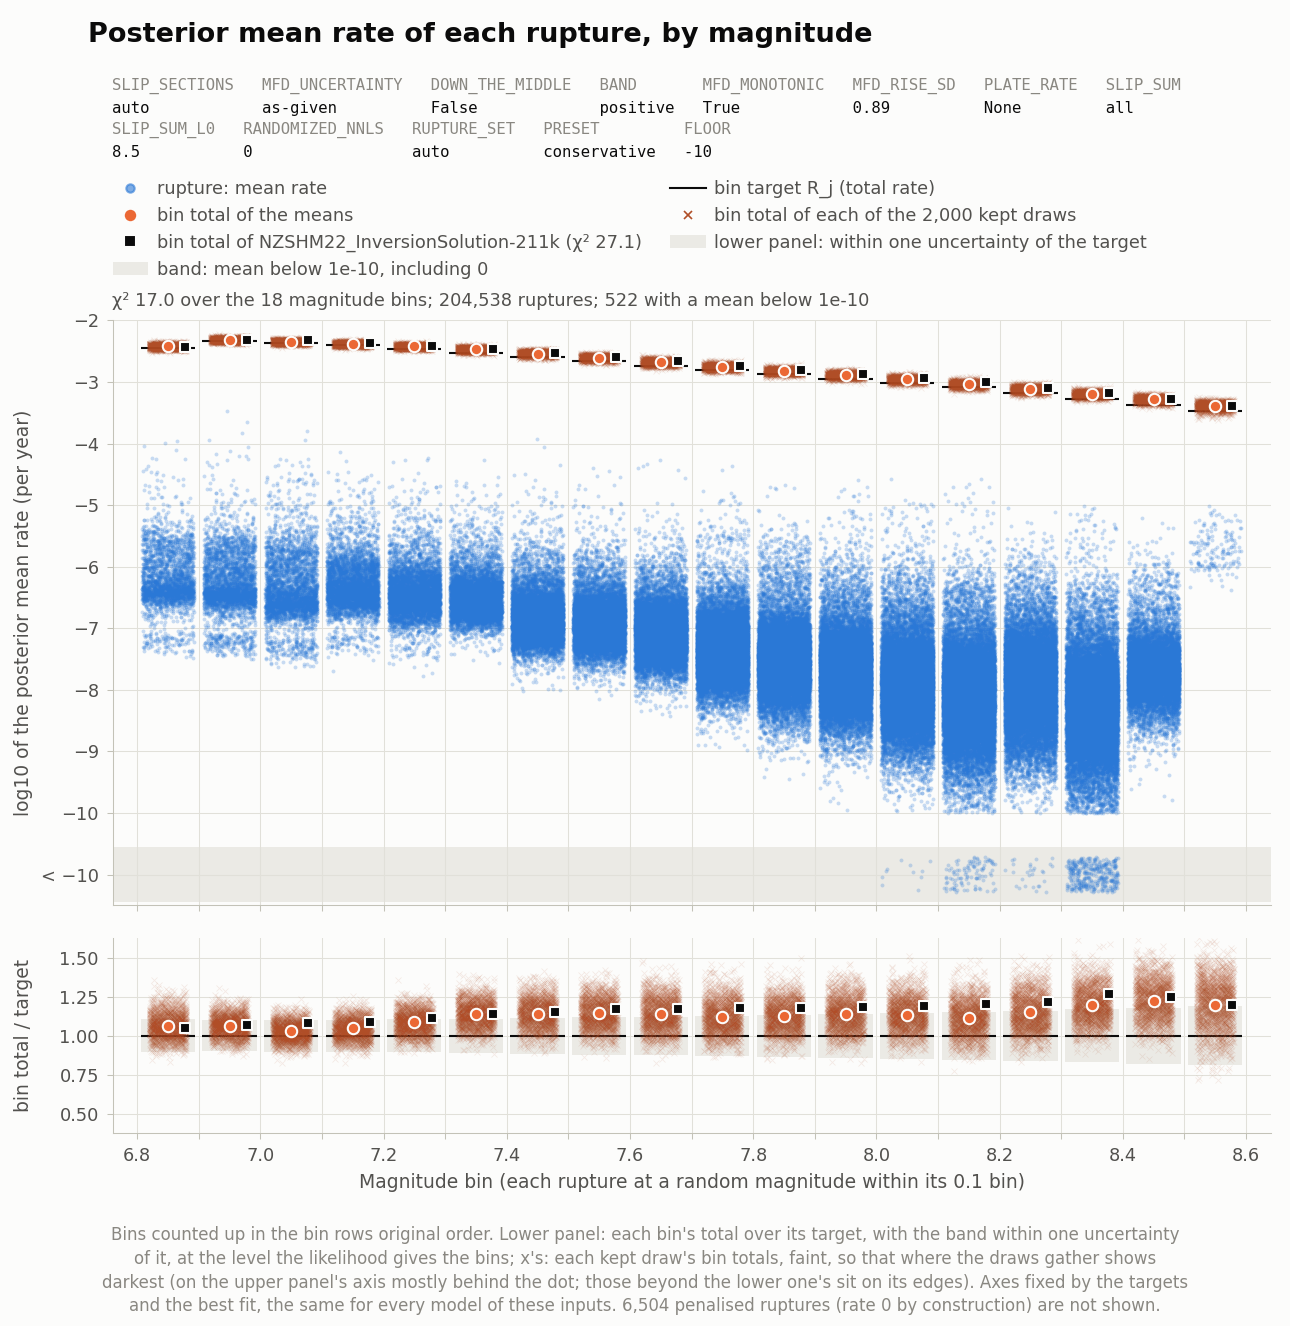

In [11]:
vec = os.path.join(results_dir(), 'rate_vectors.npz')
if os.path.exists(vec):                              # rates by magnitude, from the rate vectors' mean column
    fig = os.path.join(results_dir(), 'fig_rate_magnitude.png')
    sh('plot_rate_magnitude.py', vec, '--problem', 'cru_clean.npz', '--out', fig, '--bins-block', BIN_BLOCK,
       '--slip-block', SLIP_BLOCK, f'--diag-floor={FLOOR}', *ref_args())
    show(fig)
else:
    print('rates-by-magnitude figure skipped: it needs the rate vectors, written by the results cell above')

**Slip rates** (`fig_slip_rates.png`, with its tables in `fig_slip_rates.txt`; from the rate vectors and the predictions the runs recorded, so with or without draws): each fault section's slip-rate target against the mean model's prediction (G times the `mean` column of the rate vectors, which is also the posterior mean of the prediction), on a linear scale and on a log scale. A section's slip rate is one measurement, copied in the inputs to each of its subsections, so each section's mean prediction over its subsections is plotted as a dot, coloured so that neighbouring sections never share a colour (sections sharing a target stay stacked at it), with each of the about 3,000 kept draws' section means as a faint x at the section's target, so that where the draws gather shows darkest (with `REPRESENTATIVES = 0`, the posterior 16–84% range of the section mean as a bar instead), from the predictions the runs recorded. That spread is the model's, usually well under one measurement uncertainty, so a target outside it is no misfit in itself. The input rows are already divided by their uncertainties, which are not in the inputs, so both axes are in units of each section's measurement uncertainty (any √k weighting from cleaning is undone for display): the 1:1 line is unaffected, and a section mean in the grey band lies within one uncertainty of its target. A single subsection may stray further: in the likelihood it carries √k times that uncertainty. On the log scale the band reaches the bottom wherever a target is below 1, since a prediction of 0 is then within one uncertainty; means too small for that axis, including 0, sit on its bottom edge as triangles. The sections furthest from their targets in units of uncertainty are labelled with their original rows (`--label`, 3 by default), the keys of `subsections_posterior.csv`. The subtitle and the tables give the mean model's χ² over the slip-rate rows as the likelihood weights them (the χ² of the posterior mean, which is below the mean χ² over draws) and the share of sections within one and two uncertainties; the tables list every section's and every row's target, mean prediction, difference and ratio, and each section's posterior 16%, 50% and 84% points. Several rate vectors give one row of panels each. With the model's OpenSHA solution folder in `DATA_DIR`, that solution's own predictions (its `solution/rates.csv`) are marked too, as open black squares, with its χ² in the legend and a `reference` column in the tables.

$ /Users/rollins/Library/CloudStorage/ProtonDrive-c.rollins@gns.cri.nz-folder/Inversions/Material/cru_workflow/tools/plot_slip_rates.py spikeslab/rate_vectors.npz --problem cru_clean.npz --out spikeslab/fig_slip_rates.png --slip-block S --reference /Users/rollins/inversions/NZSHM22_Matrices-211k/NZSHM22_InversionSolution-211k/solution/rates.csv
slip-rate rows: 2312 (original rows 0-2324) in 507 sections (507 with 2-37 subsections; slip-rate sections 'auto': one measurement per section (each section's rows divided by sqrt(k) in the likelihood)); 157 distinct targets from 0.0247 to 31.6; targets and predictions in units of each section's measurement uncertainty
reference: NZSHM22_InversionSolution-211k (/Users/rollins/inversions/NZSHM22_Matrices-211k/NZSHM22_InversionSolution-211k/solution/rates.csv): its chi2 over the slip-rate rows, as the likelihood weights them, 27.6; 100% of sections within one measurement uncertainty of their targets, 100% within two; section mean / target: median 

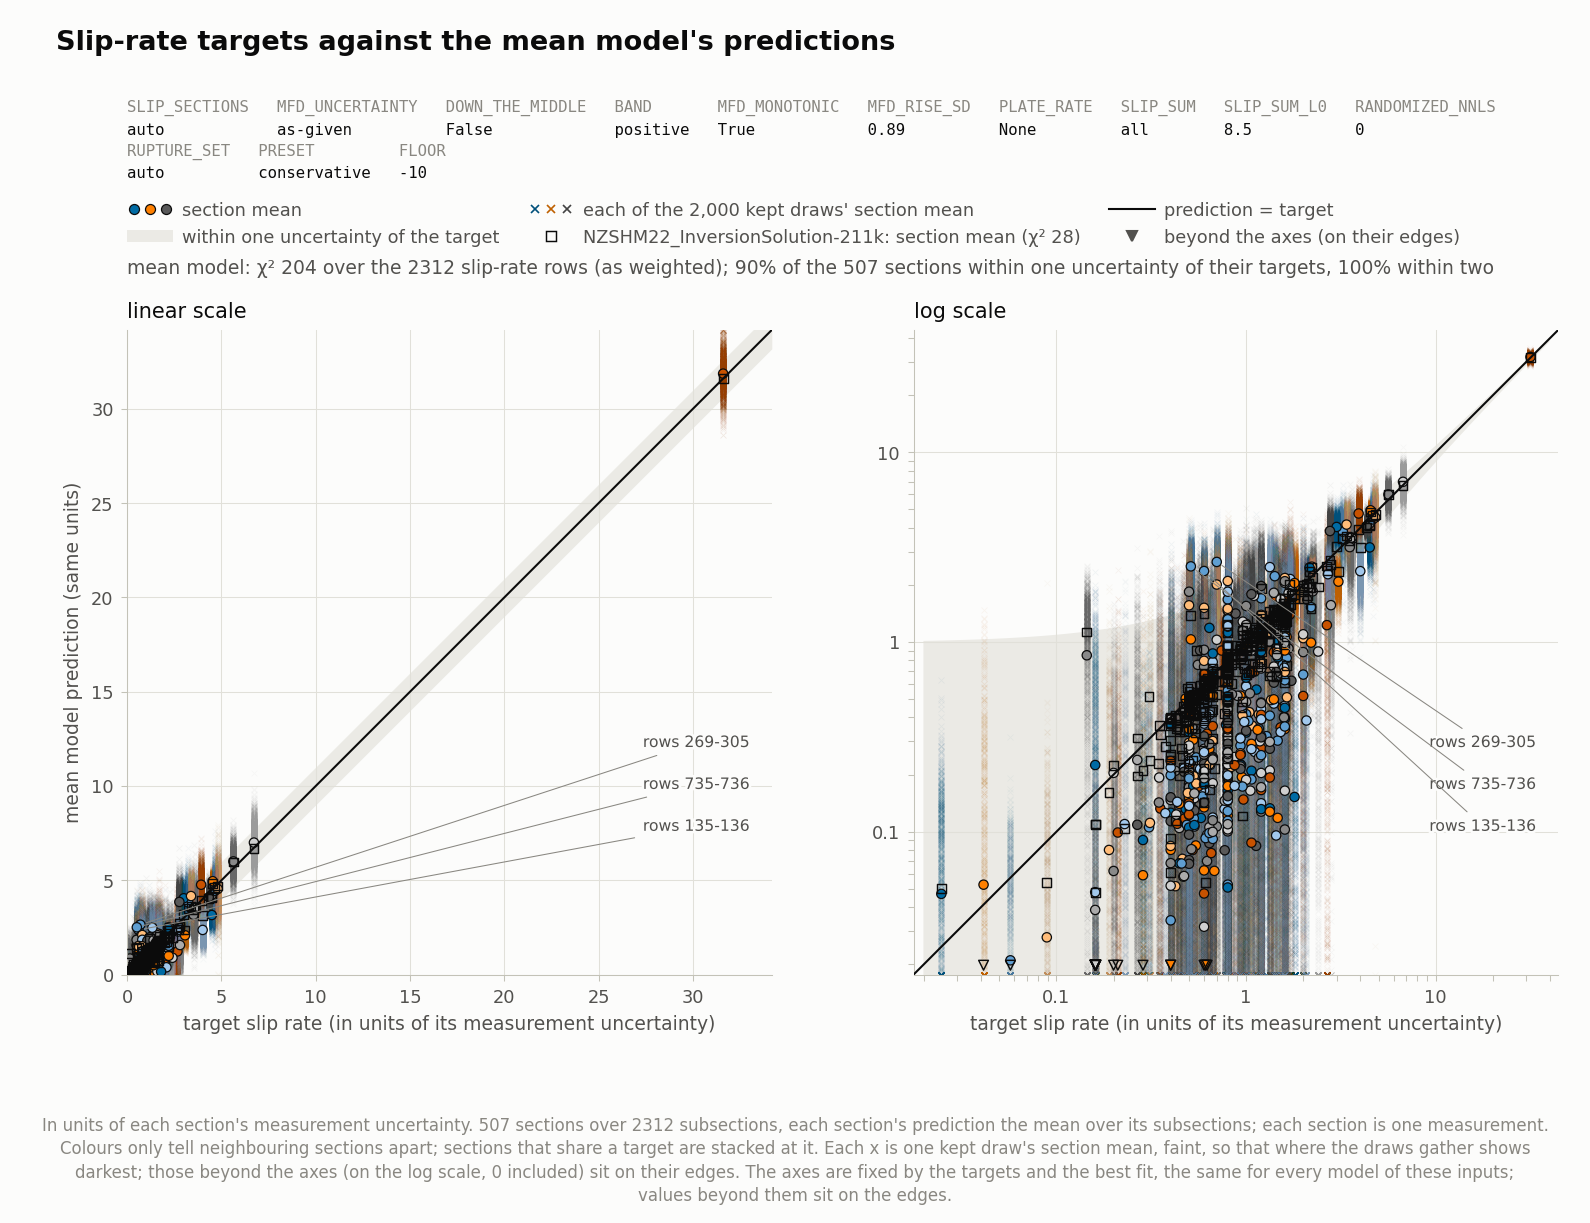

In [12]:
vec = os.path.join(results_dir(), 'rate_vectors.npz')
if os.path.exists(vec):                              # slip-rate targets against the mean model's predictions
    fig = os.path.join(results_dir(), 'fig_slip_rates.png')
    sh('plot_slip_rates.py', vec, '--problem', 'cru_clean.npz', '--out', fig, '--slip-block', SLIP_BLOCK, *ref_args())
    show(fig)
else:
    print('slip-rate figure skipped: it needs the rate vectors, written by the results cell above')

**Paleo rates** (`fig_paleo_rates.png`, with its table in `fig_paleo_rates.txt`; from the rate vectors and the predictions the runs recorded, so with or without draws): each paleo row's target against the mean model's prediction on log-log axes, with each of the about 3,000 kept draws' predictions as a faint x above the row's target (with `REPRESENTATIVES = 0`, the posterior 16–84% range of the prediction as a vertical bar instead), each row's marks in a colour unlike its neighbours'. As for the slip rates, both axes are in units of each row's uncertainty; on log axes that moves a point only along the 1:1 line, so its distance from the line is the ratio of prediction to target, and since a target in these units is one over its relative uncertainty, the best-measured sites lie furthest right. The shaded bands mark predictions within one and within two uncertainties of their targets, and the rows furthest from their targets are labelled with their original row numbers (`--label`, 4 by default). The paleo rows are every row in neither the slip-rate nor the magnitude-bin group (`--paleo-block` names them otherwise). The subtitle and the table give the mean model's χ² over these rows and the share within one and two uncertainties; the table lists every row's target, mean prediction, posterior 16%, 50% and 84% points, difference and ratio. Several rate vectors give one panel each. With the model's OpenSHA solution folder in `DATA_DIR`, that solution's own predictions (its `solution/rates.csv`) are marked too, as open black squares, with its χ² in the legend and a `reference` column in the table.

$ /Users/rollins/Library/CloudStorage/ProtonDrive-c.rollins@gns.cri.nz-folder/Inversions/Material/cru_workflow/tools/plot_paleo_rates.py spikeslab/rate_vectors.npz --problem cru_clean.npz --out spikeslab/fig_paleo_rates.png --slip-block S --bins-block MFD --reference /Users/rollins/inversions/NZSHM22_Matrices-211k/NZSHM22_InversionSolution-211k/solution/rates.csv
paleo rows: 65 (the rows in neither 'S' nor 'MFD': row block 'B8:var'; original rows 8863-8927); targets from 1.35 to 10.7; targets and predictions in units of each row's uncertainty (a target is one over its relative uncertainty)
reference: NZSHM22_InversionSolution-211k (/Users/rollins/inversions/NZSHM22_Matrices-211k/NZSHM22_InversionSolution-211k/solution/rates.csv): its chi2 over the paleo rows 72.6; 65% of rows within one uncertainty of their targets, 91% within two; prediction / target: median 0.78 (5-95%: 0.31 to 1.09); its rates on the 298 ruptures cleaning removed (5.95e-05 per year, 0.14% of its total) are not in th

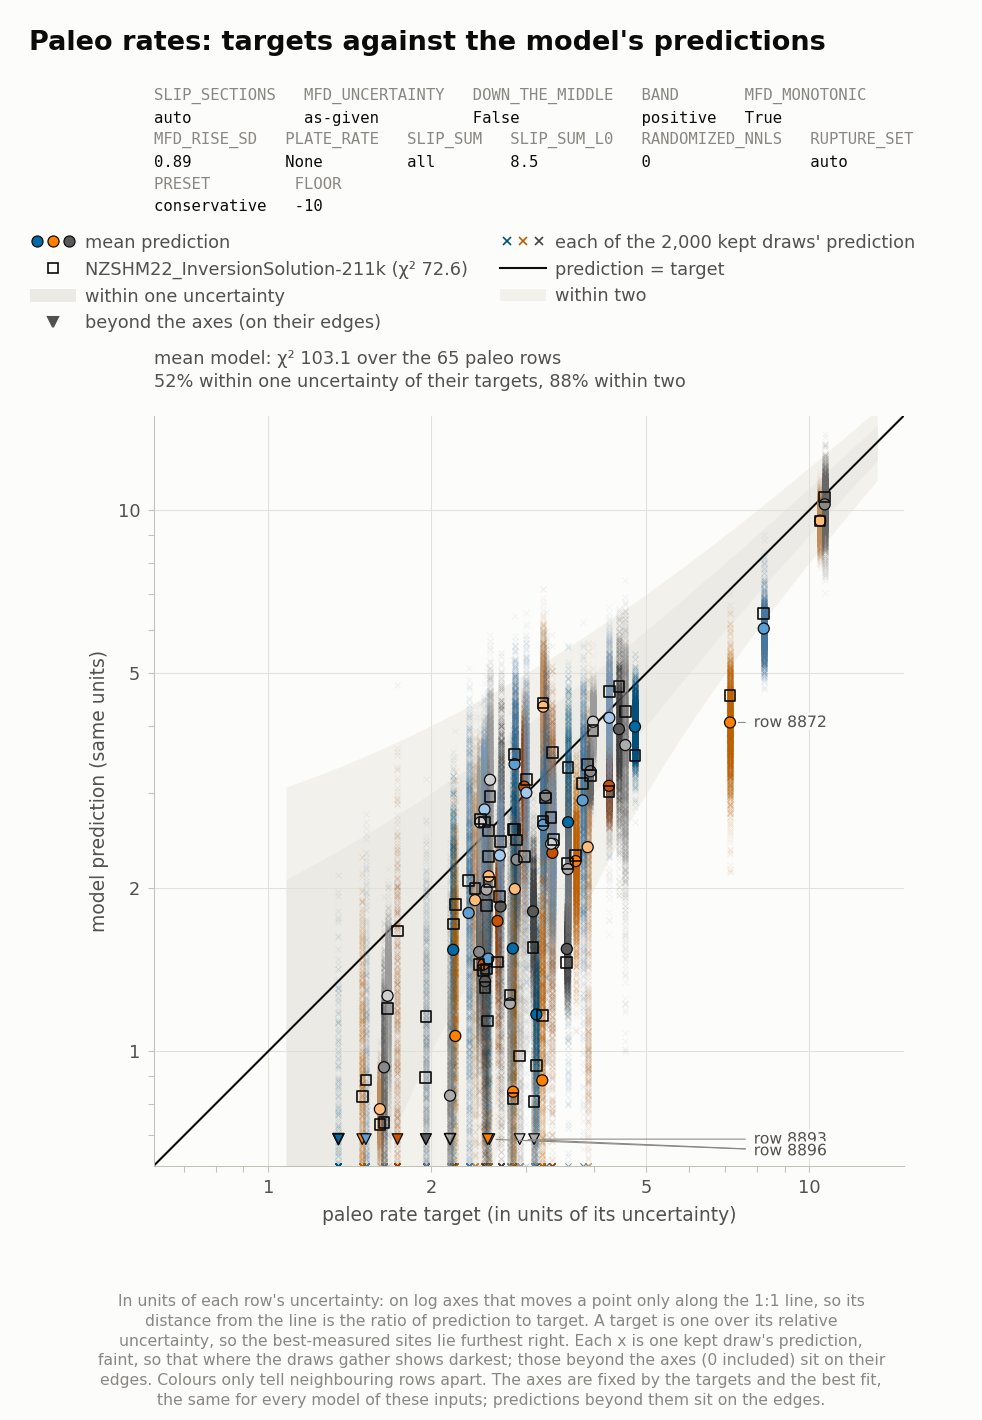

In [13]:
vec = os.path.join(results_dir(), 'rate_vectors.npz')
if os.path.exists(vec):                              # paleo-rate targets against the model's predictions
    fig = os.path.join(results_dir(), 'fig_paleo_rates.png')
    sh('plot_paleo_rates.py', vec, '--problem', 'cru_clean.npz', '--out', fig, '--slip-block', SLIP_BLOCK,
       '--bins-block', BIN_BLOCK, *ref_args())
    show(fig)
else:
    print('paleo-rate figure skipped: it needs the rate vectors, written by the results cell above')

**Faults one by one** (`fig_slip_sections.png`, `fig_slip_sections_ruptures_1.png` and `_2.png`, and `fig_slip_sections_ruptures_by_magnitude_1.png` and `_2.png`, each set with its table in `.txt`; `plot_slip_sections.py`): with the model's rupture set (`RUPTURE_SET`), its named faults (`named_faults.json`), one column each from the most isolated to the best connected. The first figure shows each fault's posterior slip-rate prediction (each of the about 3,000 kept draws as a faint x, and the mean; with `REPRESENTATIVES = 0`, the 16–84% and 2.5–97.5% ranges and median instead) against its target, in units of its sections' uncertainties, with the share of draws in which no rupture crossing it is on and the number of other sections sharing a rupture with it. The second counts each fault's ruptures by their posterior mean rates, with each kept draw's counts of the ruptures on in it as x's; the third sums the rates by magnitude bin, the fault's rate of events per bin, each kept draw's sums as x's with the posterior mean as a circle, and a strip marked 0 whose opacity is the share of draws without an event in the bin; both show the model's OpenSHA solution's rates of the same ruptures as black outlines, and both come in two parts for readability: the first 18 faults six across, then the rest five across. Without a rupture set, 30 slip-rate sections chosen across the range of connectivity take the faults' place.

$ /Users/rollins/Library/CloudStorage/ProtonDrive-c.rollins@gns.cri.nz-folder/Inversions/Material/cru_workflow/tools/plot_slip_sections.py spikeslab/rate_vectors.npz --problem cru_clean.npz --out spikeslab/fig_slip_sections.png --slip-block S --bins-block MFD --ruptures /Users/rollins/inversions/NZSHM22_Matrices-211k/NZSHM22_InversionSolution-211k/ruptures --reference /Users/rollins/inversions/NZSHM22_Matrices-211k/NZSHM22_InversionSolution-211k/solution/rates.csv
slip rates fault by fault: the 33 named faults of named_faults.json, from the most isolated to the most connected (other sections sharing a rupture with each: 0 to 125, median 34); targets and predictions in units of each section's measurement uncertainty (the mean over the subsections)
connectivity, from the cleaned problem's slip-rate rows (for the ruptures cleaning kept, the rupture set's indices.csv): "connected" counts the other sections (holding none of the fault's subsections) sharing at least one rupture with it, "rup

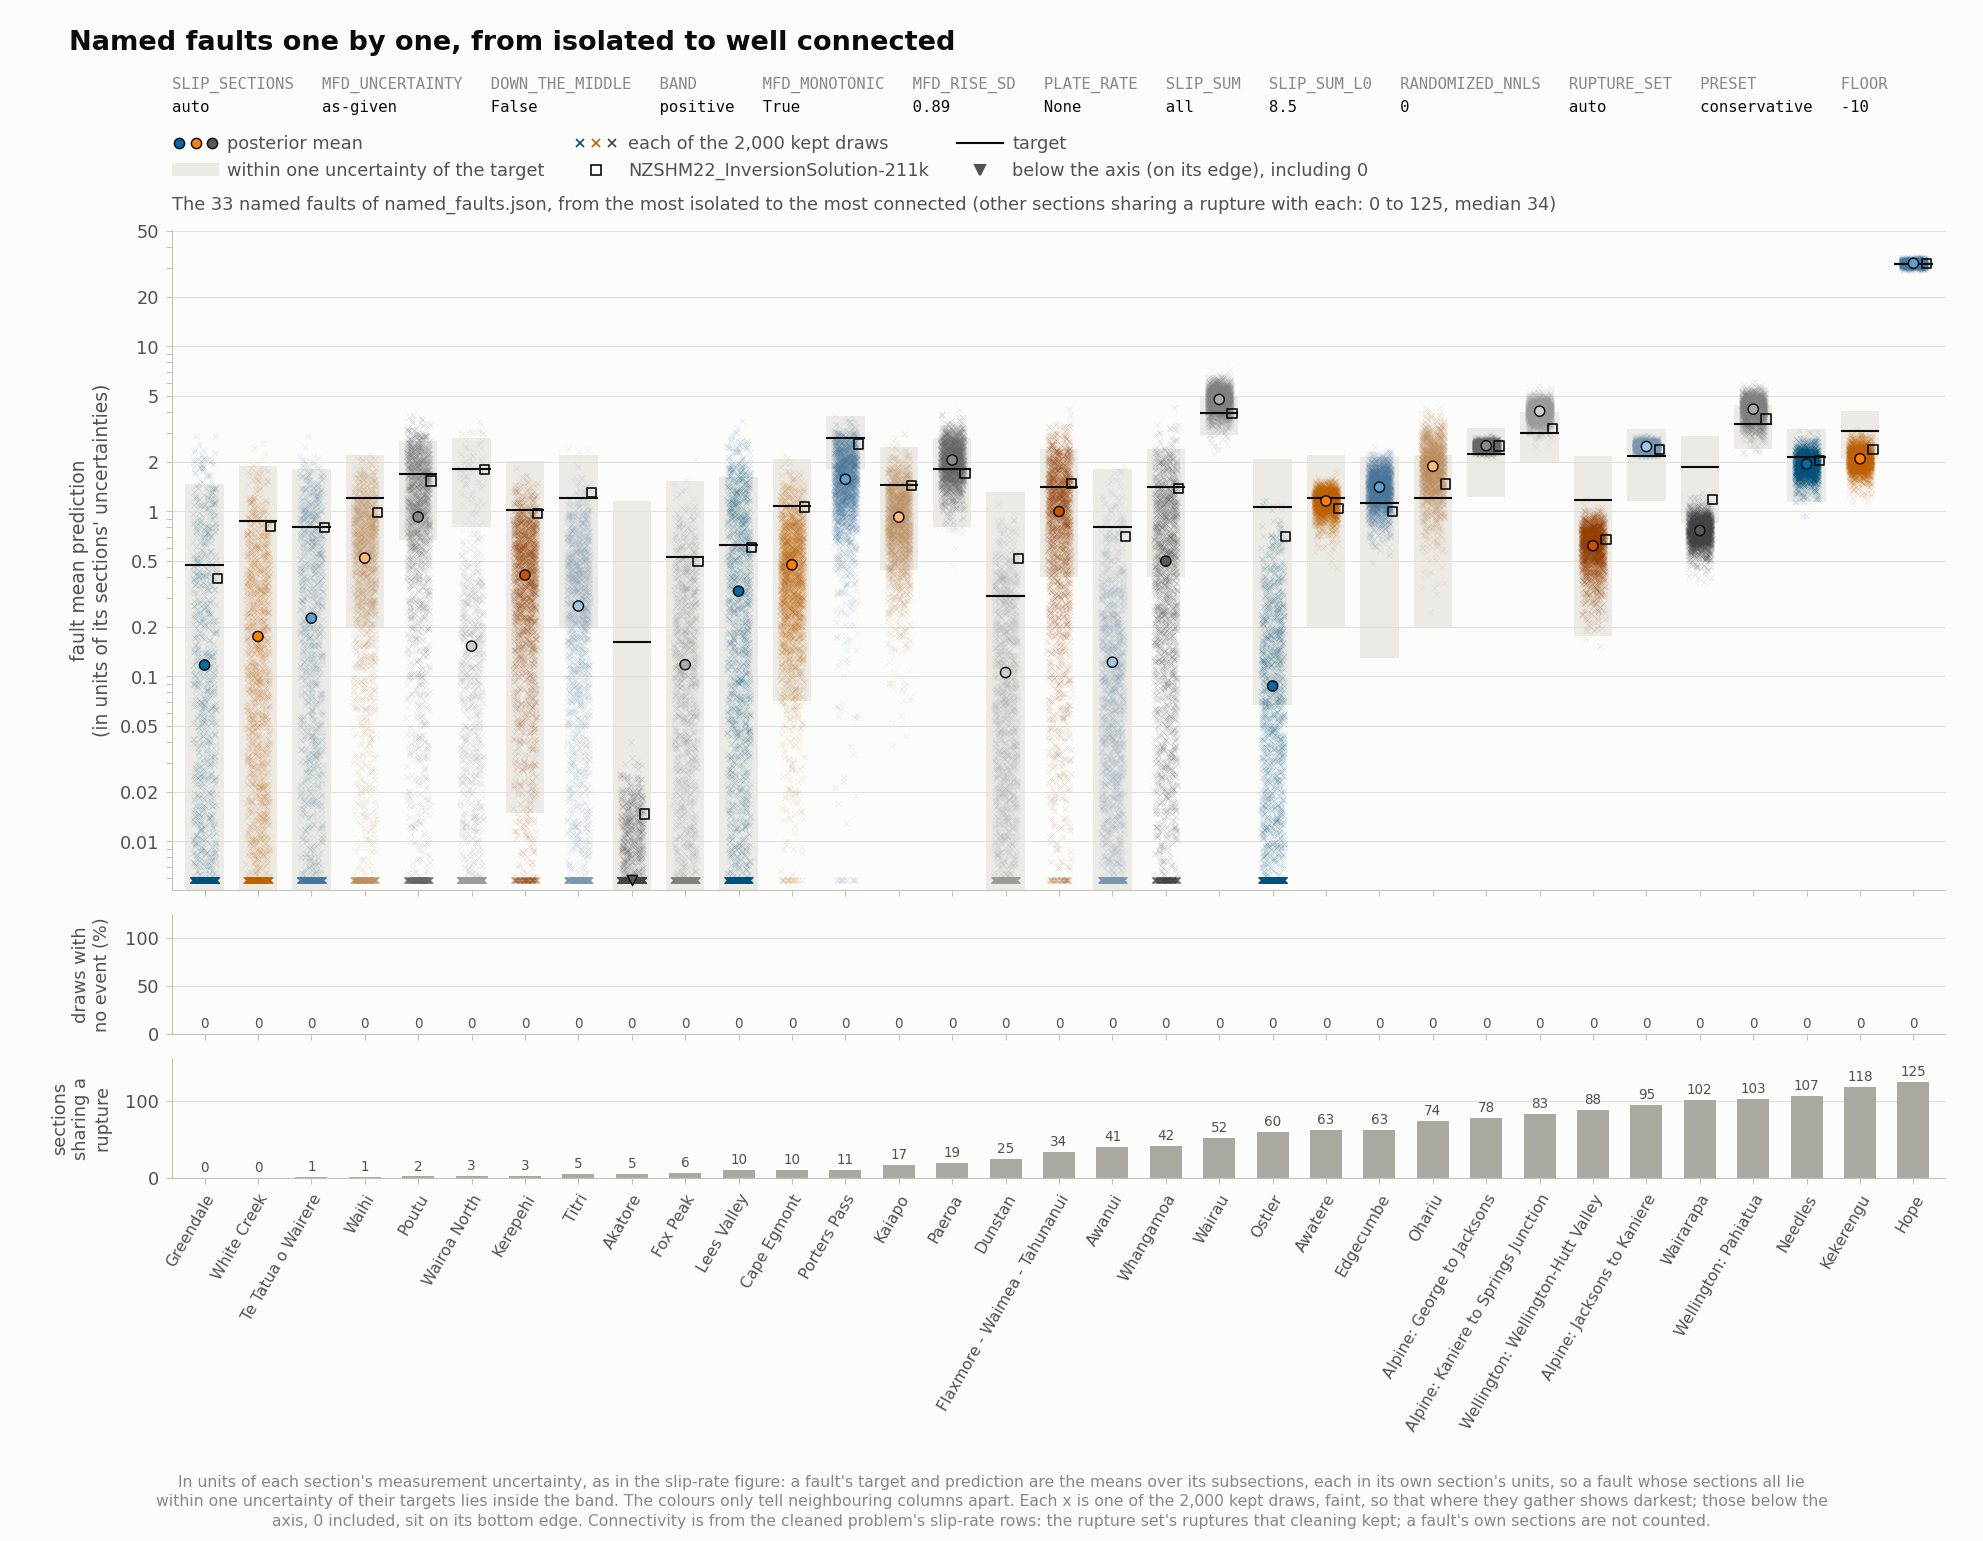

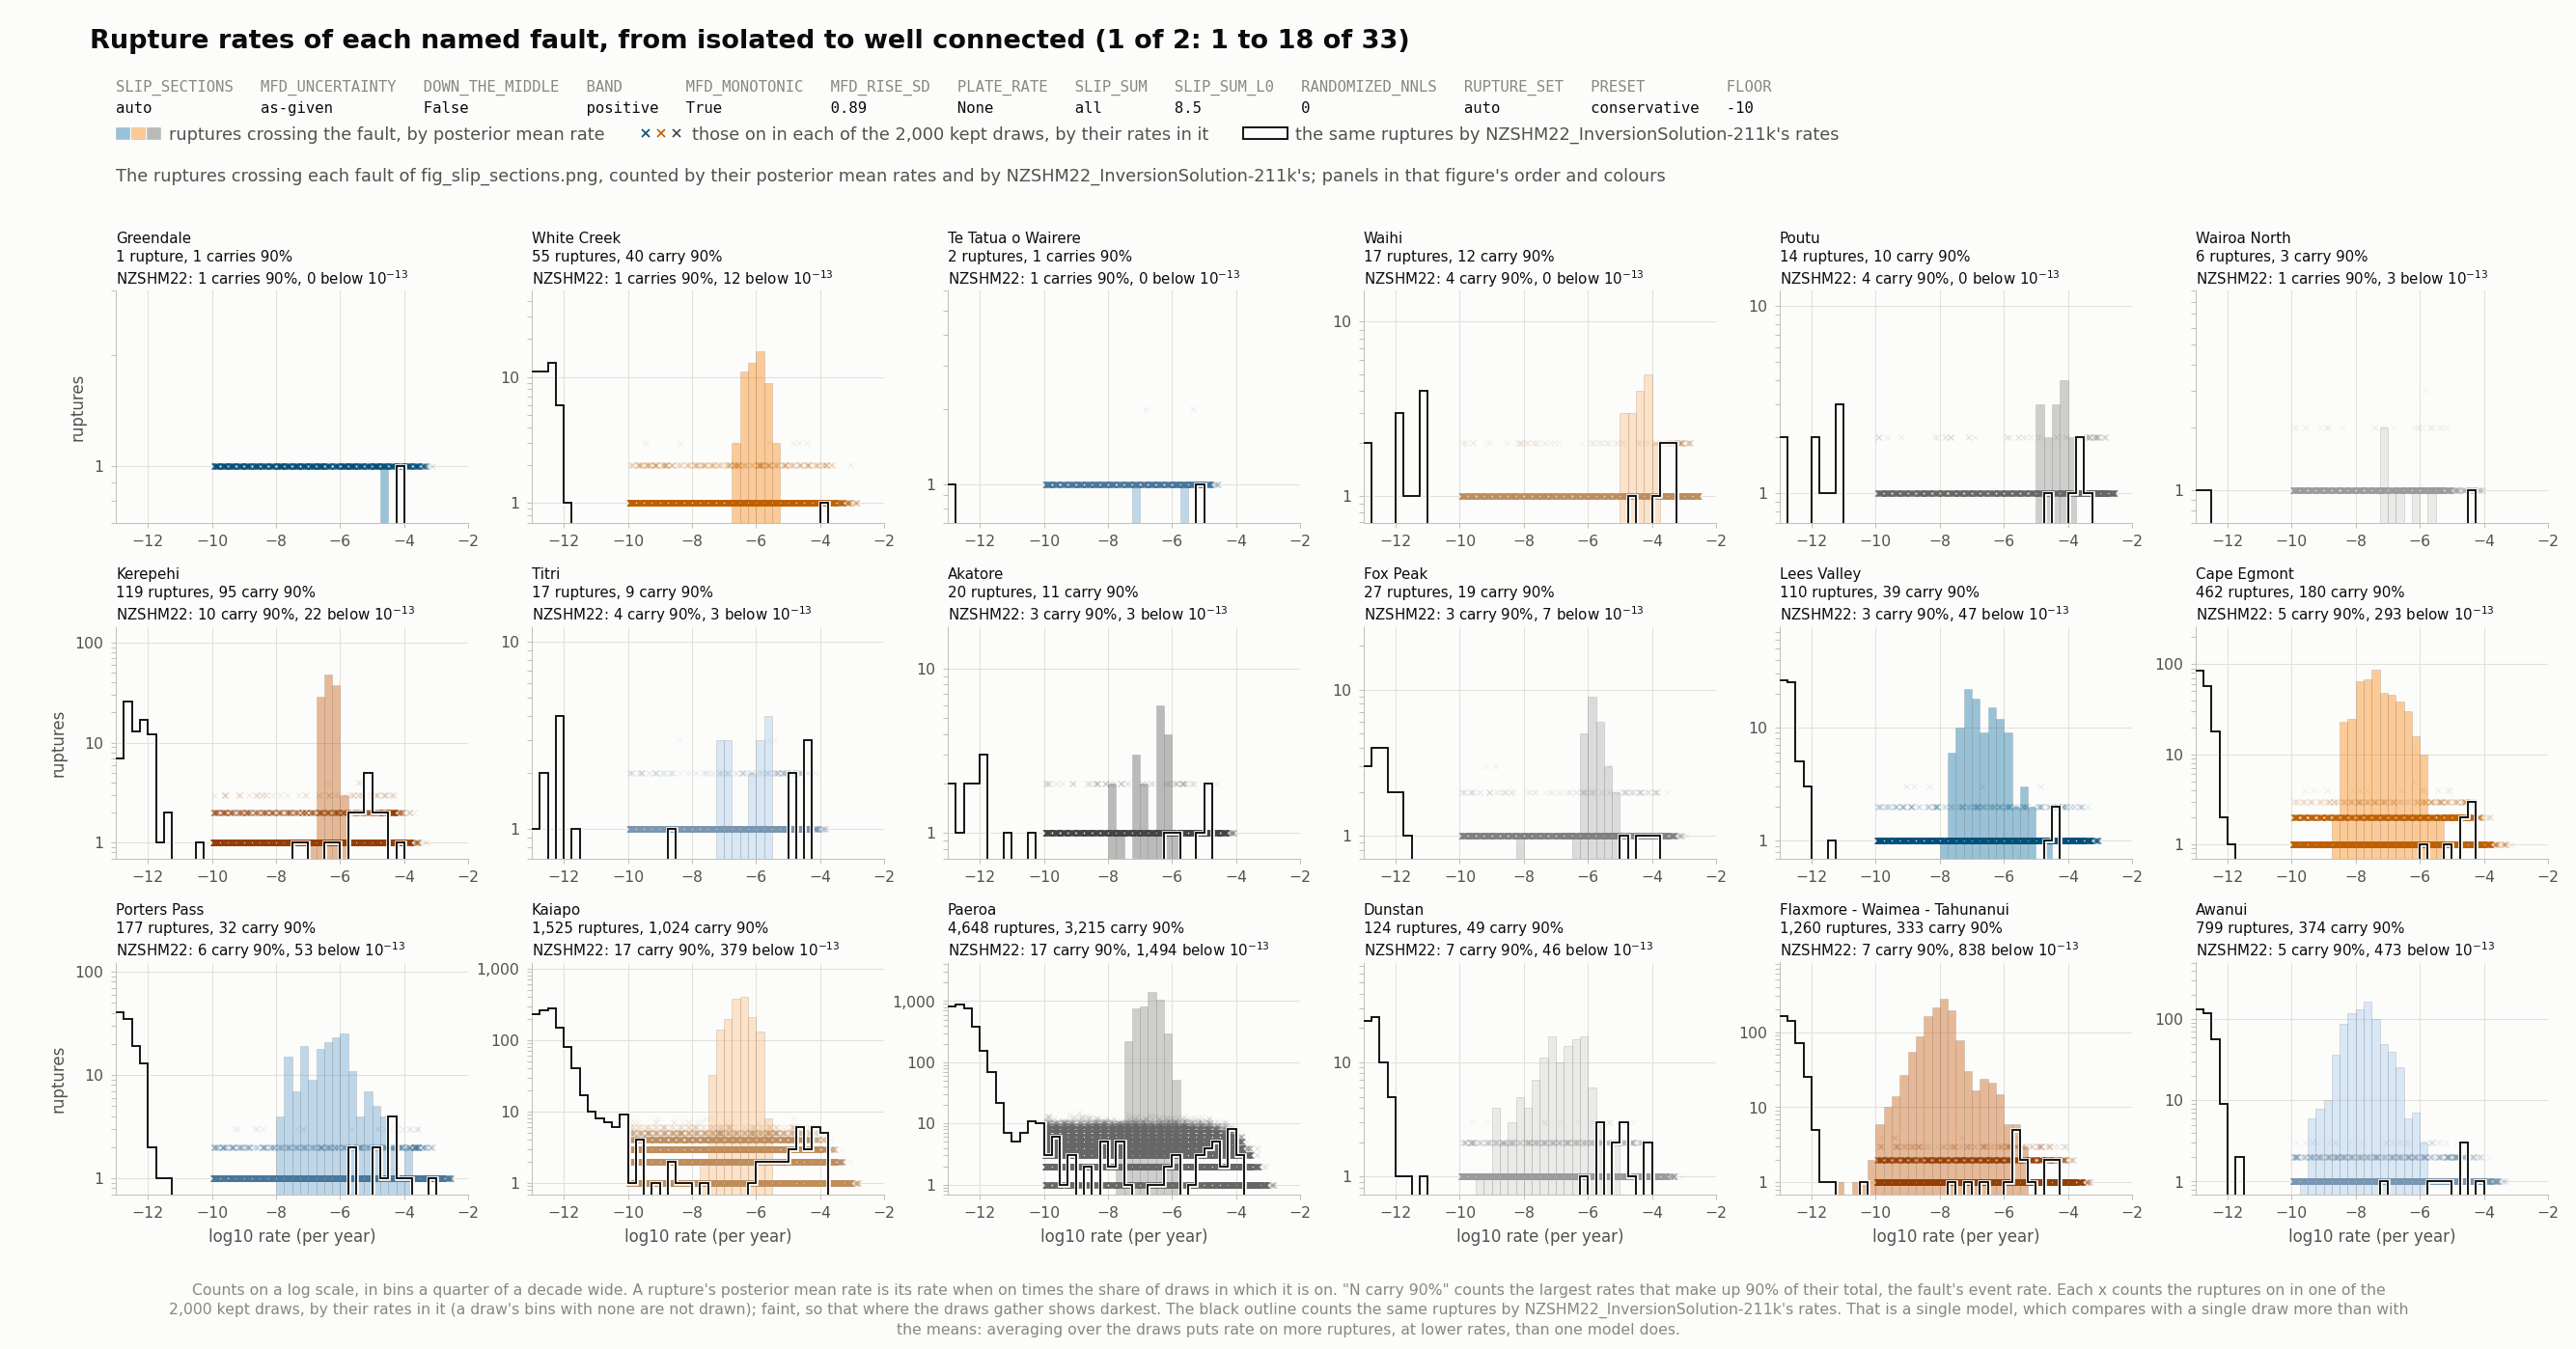

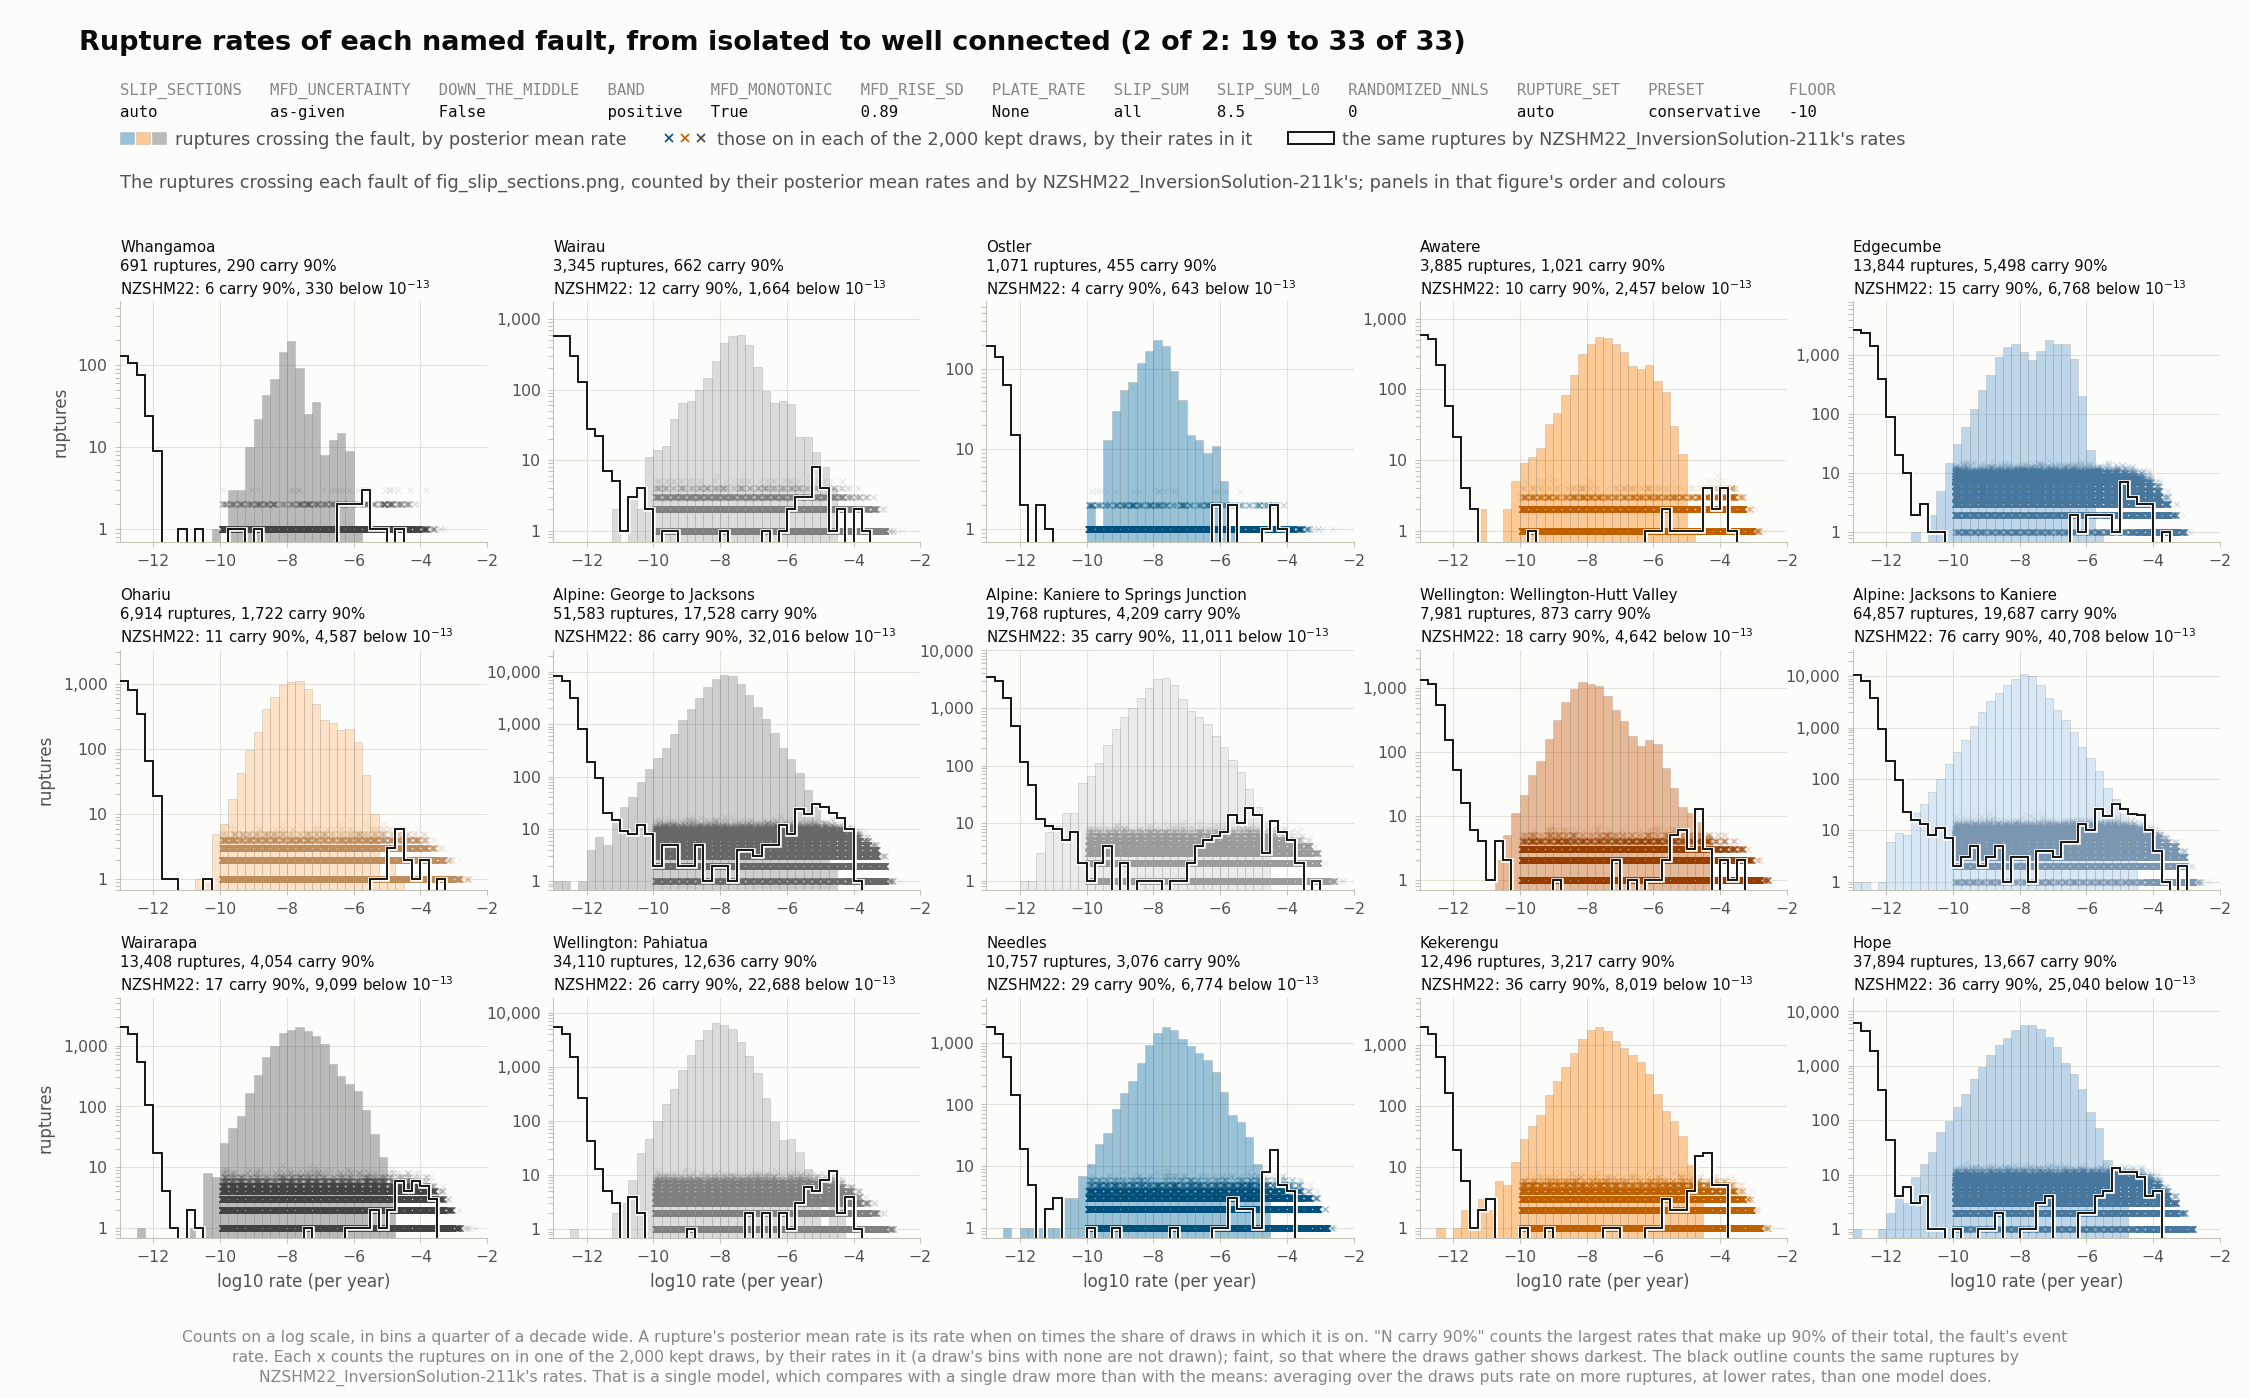

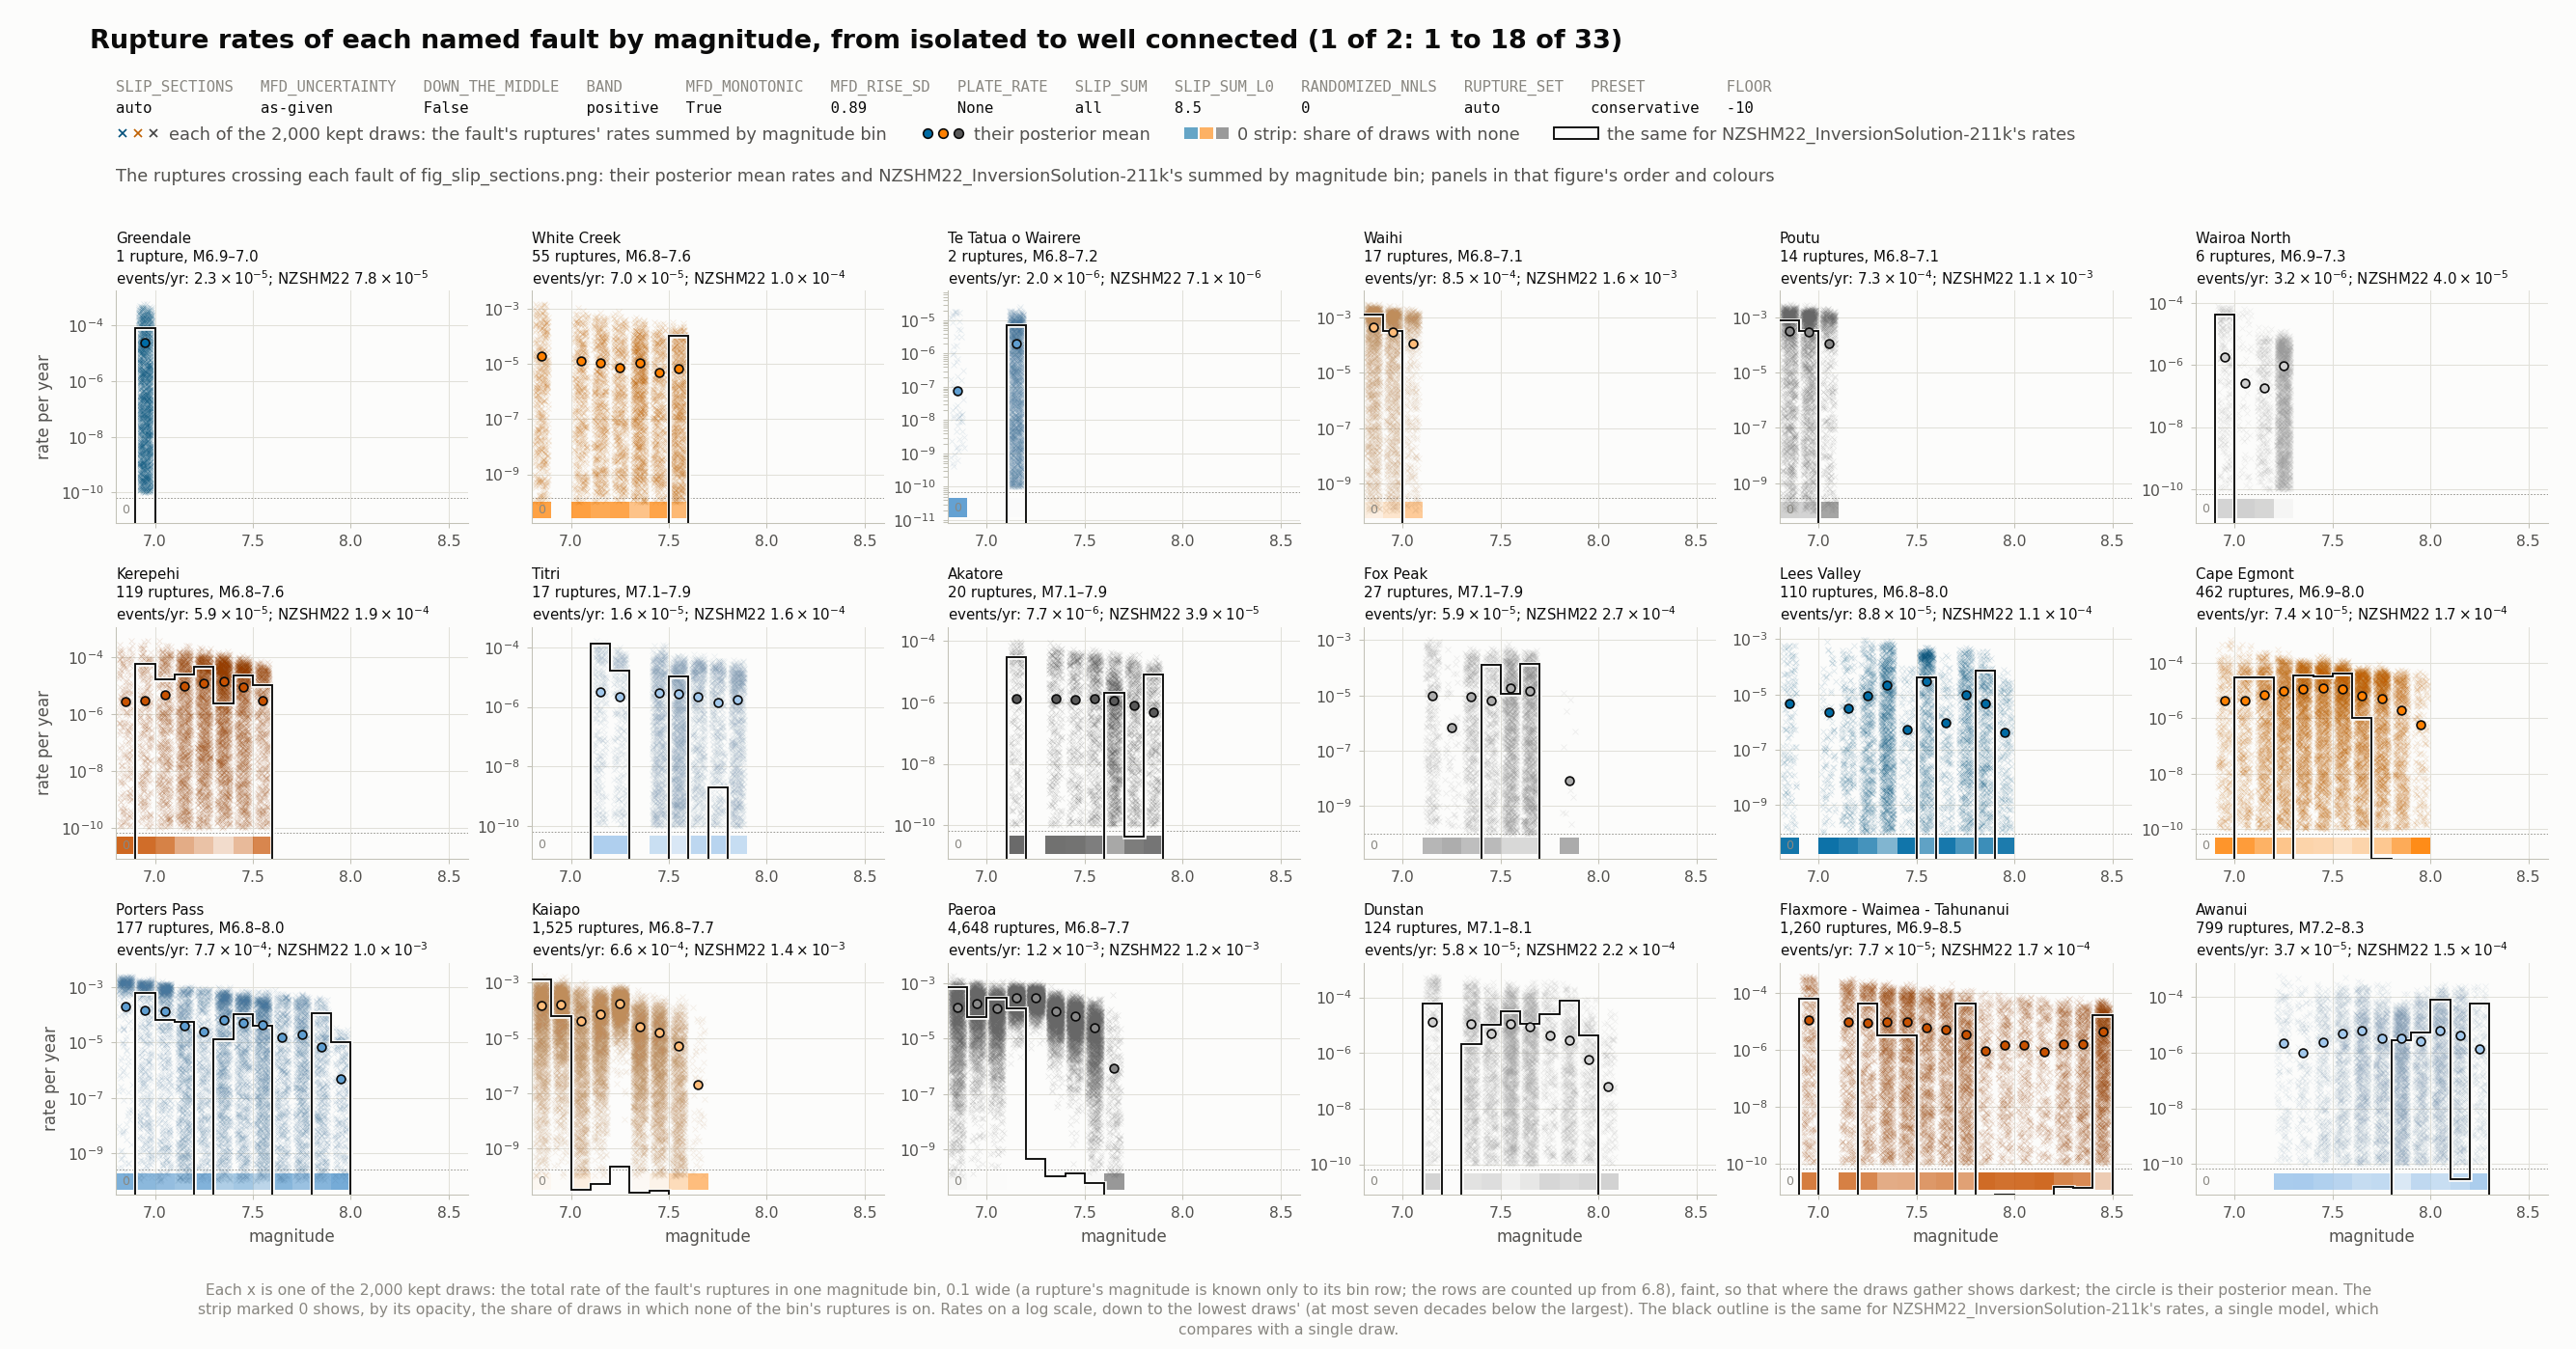

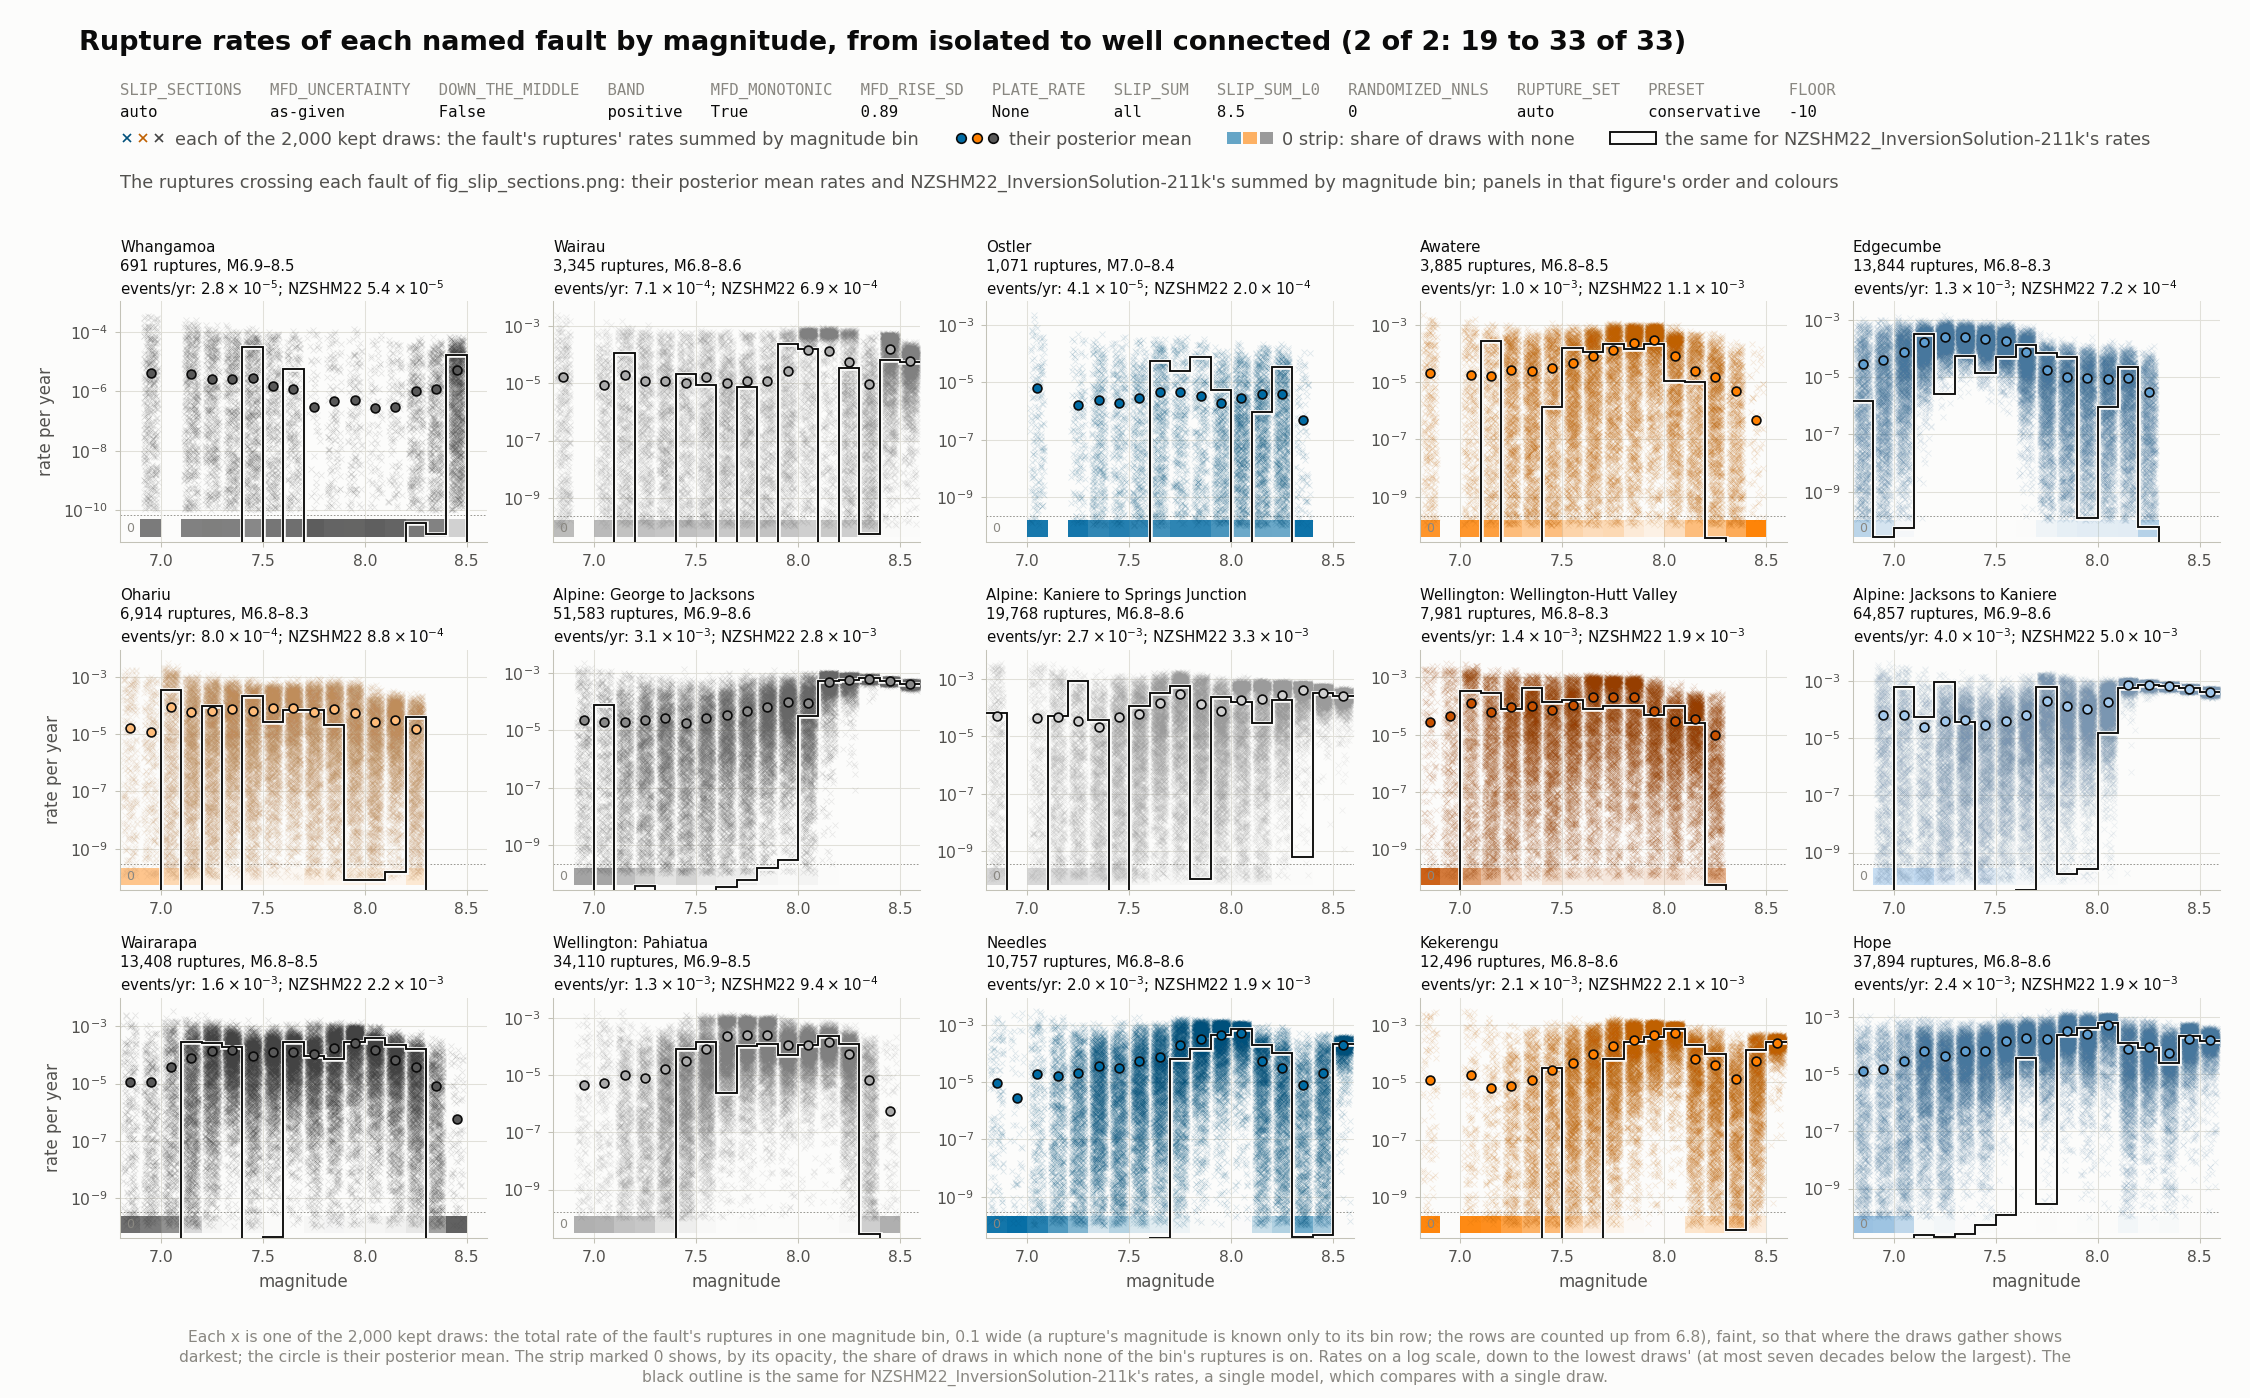

In [14]:
vec = os.path.join(results_dir(), 'rate_vectors.npz')
if os.path.exists(vec):                              # the named faults one by one, and their ruptures
    fig = os.path.join(results_dir(), 'fig_slip_sections.png')
    _rd = rupture_dir()                              # its named_faults.json names the faults
    sh('plot_slip_sections.py', vec, '--problem', 'cru_clean.npz', '--out', fig, '--slip-block', SLIP_BLOCK,
       '--bins-block', BIN_BLOCK, *(['--ruptures', _rd] if _rd else []), *ref_args())
    for _f in ('', '_ruptures_1', '_ruptures_2', '_ruptures_by_magnitude_1', '_ruptures_by_magnitude_2'):
        if os.path.exists(fig.replace('.png', _f + '.png')):   # the rupture figures come in two parts
            show(fig.replace('.png', _f + '.png'))
else:
    print('fault-by-fault figures skipped: they need the rate vectors, written by the results cell above')

**The plate rate and the summed slip rates** (`plate_rate.txt`; `plate_rate.py`): with the model's rupture set (`RUPTURE_SET`), the share of the Pacific–Australia plate rate that the crustal faults take up in each of the eight strips between the Alpine and Cook Strait edges, from SW to NE: of the fault model's slip rates, the targets, the best fit, the posterior mean and the kept draws (their 2.5–97.5% range and, with `PLATE_RATE`, the share of them inside its limits: all), with the faults that take most of each strip's share; then the summed slip rates' term (`SLIP_SUM`'s), SW of the edges, between them and NE of them, for the best fit, the posterior mean and the kept draws, with the strips furthest from their target sums. Written whether or not either option is set, so that runs with and without them compare.

In [15]:
vec = os.path.join(results_dir(), 'rate_vectors.npz')
_rd = rupture_dir()                                  # the faults' traces, rakes and dips, the ruptures' slips
if not _rd:
    print("plate-rate report skipped: it needs the model's OpenSHA rupture set (RUPTURE_SET)")
elif os.path.exists(vec):
    sh('plate_rate.py', _rd, '--run', results_dir(), '--problem', 'cru_clean.npz', '--slip-block', SLIP_BLOCK,
       '--slip-sum-region', SLIP_SUM or 'all', '--slip-sum-l0', SLIP_SUM_L0,
       *(['--limits', f'{PLATE_RATE[0]:g},{PLATE_RATE[1]:g}'] if PLATE_RATE else []))
else:
    print('plate-rate report skipped: it needs the rate vectors, written by the results cell above')

$ /Users/rollins/Library/CloudStorage/ProtonDrive-c.rollins@gns.cri.nz-folder/Inversions/Material/cru_workflow/tools/plate_rate.py /Users/rollins/inversions/NZSHM22_Matrices-211k/NZSHM22_InversionSolution-211k/ruptures --run spikeslab --problem cru_clean.npz --slip-block S --slip-sum-region all --slip-sum-l0 8.5


plate rate: the share of the relative plate motion that the faults take up, strip by strip from SW to NE
   8 strips of 76 km between the cross-sections through 167.83 E 44.53 S and 174.4258 E 41.6758 S, perpendicular to the plate motion (Euler pole 61.04 S 184.19 E, 1.08 deg/Myr; 34.7-46.2 mm/yr): 1008 subsections
   across the plate motion (should add up to 0), the fault model: +0.19 -0.00 -0.01 +0.01 -0.07 -0.07 +0.05 +0.08
   strip      fault model         targets        best fit  posterior mean     kept draws, 2.5-97.5%   main contributors (fault model)
       1            0.689           0.551           0.654           0.601           0.546 -   0.659   Alpine 0.66, Hollyford 0.00, Madagascar 0.00, Barn 0.00
       2            0.701           0.561           0.680           0.614           0.547 -   0.680   Alpine 0.65, Akatore 0.01, Gimmerburn 0.00, Green Island 0.00
       3            0.677           0.541           0.641           0.598           0.527 -   0.675   Alpine 0.65

**The best fit's figures** (`nnls/fig_slip_rates_nnls.png`, `nnls/fig_rate_magnitude_nnls.png` and `nnls/fig_paleo_rates_nnls.png`, each with its table in `.txt`): the best nonnegative fit from cleaning, drawn as the posterior's are above and with the same axes. They come last, and every fit figure looks for the model's OpenSHA solution only when it is drawn, so a solution whose inversion finishes while the notebook runs is still marked on them.

$ /Users/rollins/Library/CloudStorage/ProtonDrive-c.rollins@gns.cri.nz-folder/Inversions/Material/cru_workflow/tools/plot_slip_rates.py nnls/nnls_vectors.npz:best fit (NNLS) --problem cru_clean.npz --out nnls/fig_slip_rates_nnls.png --slip-block S --reference /Users/rollins/inversions/NZSHM22_Matrices-211k/NZSHM22_InversionSolution-211k/solution/rates.csv
slip-rate rows: 2312 (original rows 0-2324) in 507 sections (507 with 2-37 subsections; slip-rate sections 'auto': one measurement per section (each section's rows divided by sqrt(k) in the likelihood)); 157 distinct targets from 0.0247 to 31.6; targets and predictions in units of each section's measurement uncertainty
reference: NZSHM22_InversionSolution-211k (/Users/rollins/inversions/NZSHM22_Matrices-211k/NZSHM22_InversionSolution-211k/solution/rates.csv): its chi2 over the slip-rate rows, as the likelihood weights them, 27.6; 100% of sections within one measurement uncertainty of their targets, 100% within two; section mean / targ

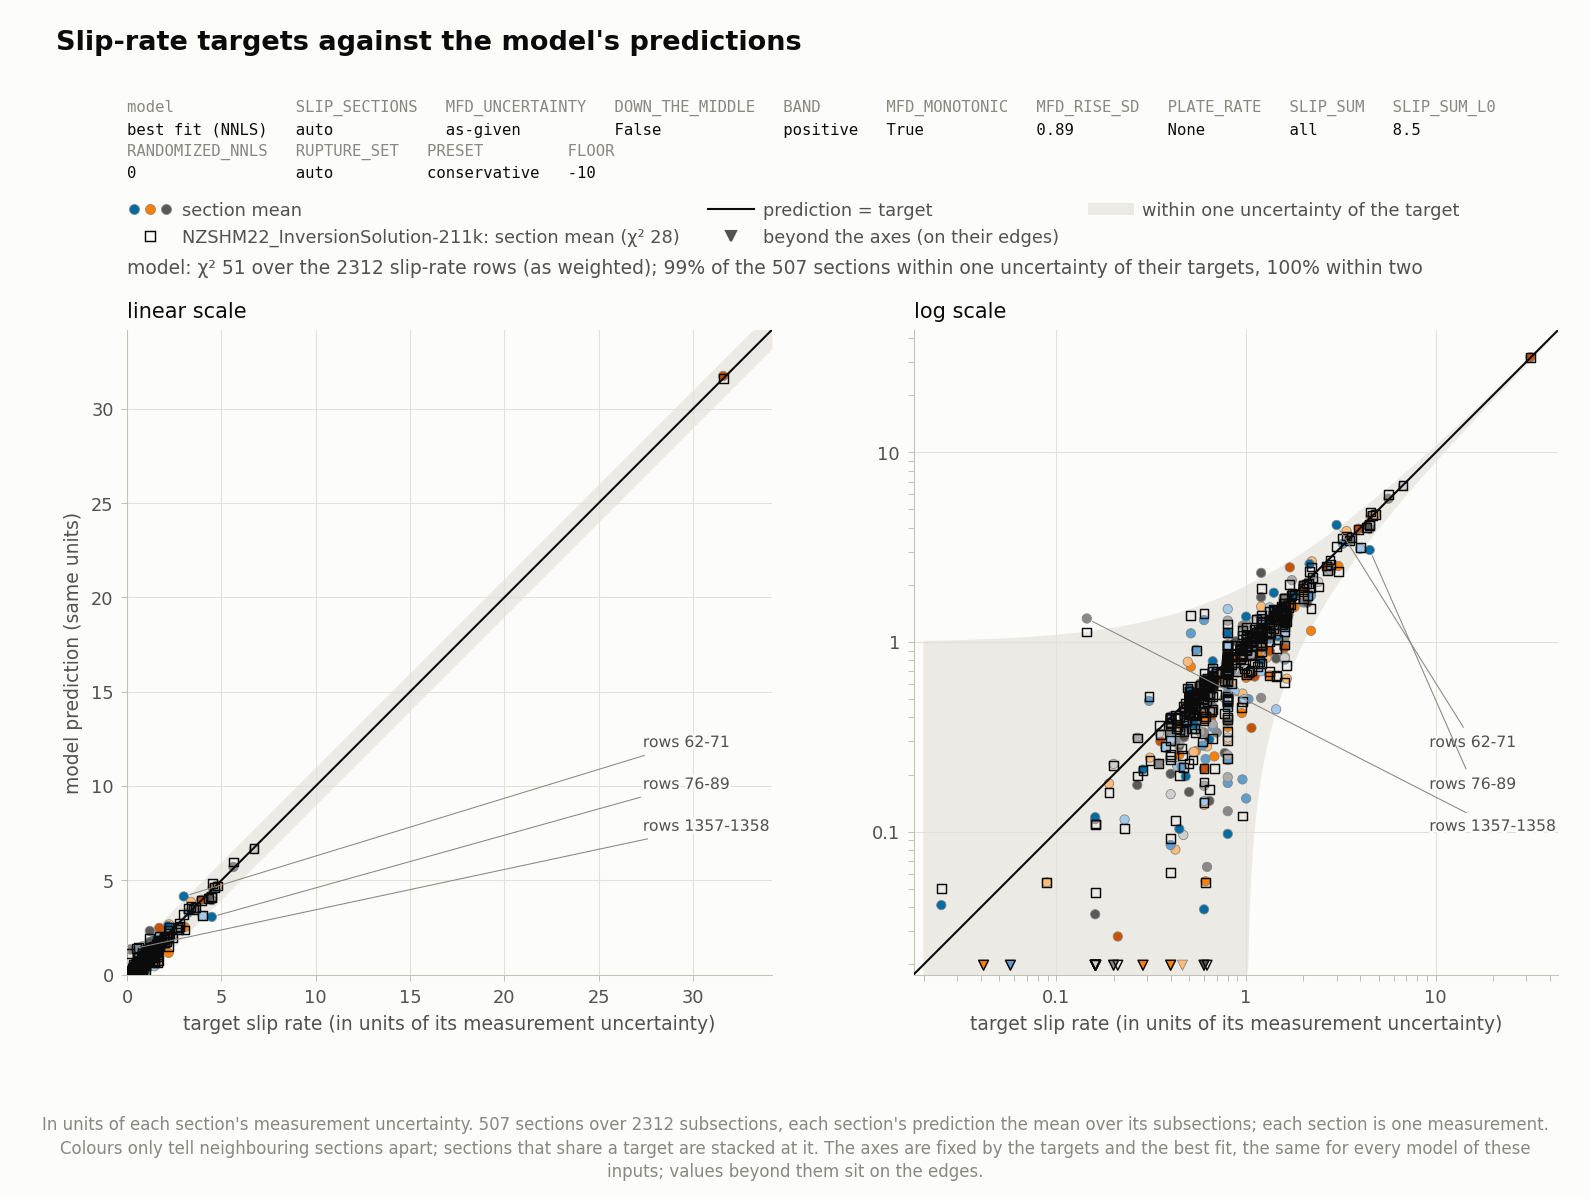

$ /Users/rollins/Library/CloudStorage/ProtonDrive-c.rollins@gns.cri.nz-folder/Inversions/Material/cru_workflow/tools/plot_rate_magnitude.py nnls/nnls_vectors.npz:best fit (NNLS) --problem cru_clean.npz --out nnls/fig_rate_magnitude_nnls.png --slip-block S --bins-block MFD --diag-floor=-10 --reference /Users/rollins/inversions/NZSHM22_Matrices-211k/NZSHM22_InversionSolution-211k/solution/rates.csv
magnitude bins: 18 bin rows (original rows 8845-8862), counted up from 6.80-6.90 in steps of 0.1; 204,538 ruptures, each drawn at a random magnitude within its bin
order check: the median number of subsections per rupture goes from 12 (6.80-6.90) to 112 (8.50-8.60), rank correlation with magnitude +0.98
settings: model best fit (NNLS), SLIP_SECTIONS auto, MFD_UNCERTAINTY as-given, DOWN_THE_MIDDLE False, BAND positive, MFD_MONOTONIC True, MFD_RISE_SD 0.89, PLATE_RATE None, SLIP_SUM all, SLIP_SUM_L0 8.5, RANDOMIZED_NNLS 0, RUPTURE_SET auto, PRESET conservative, FLOOR -10

reference: NZSHM22_Inve

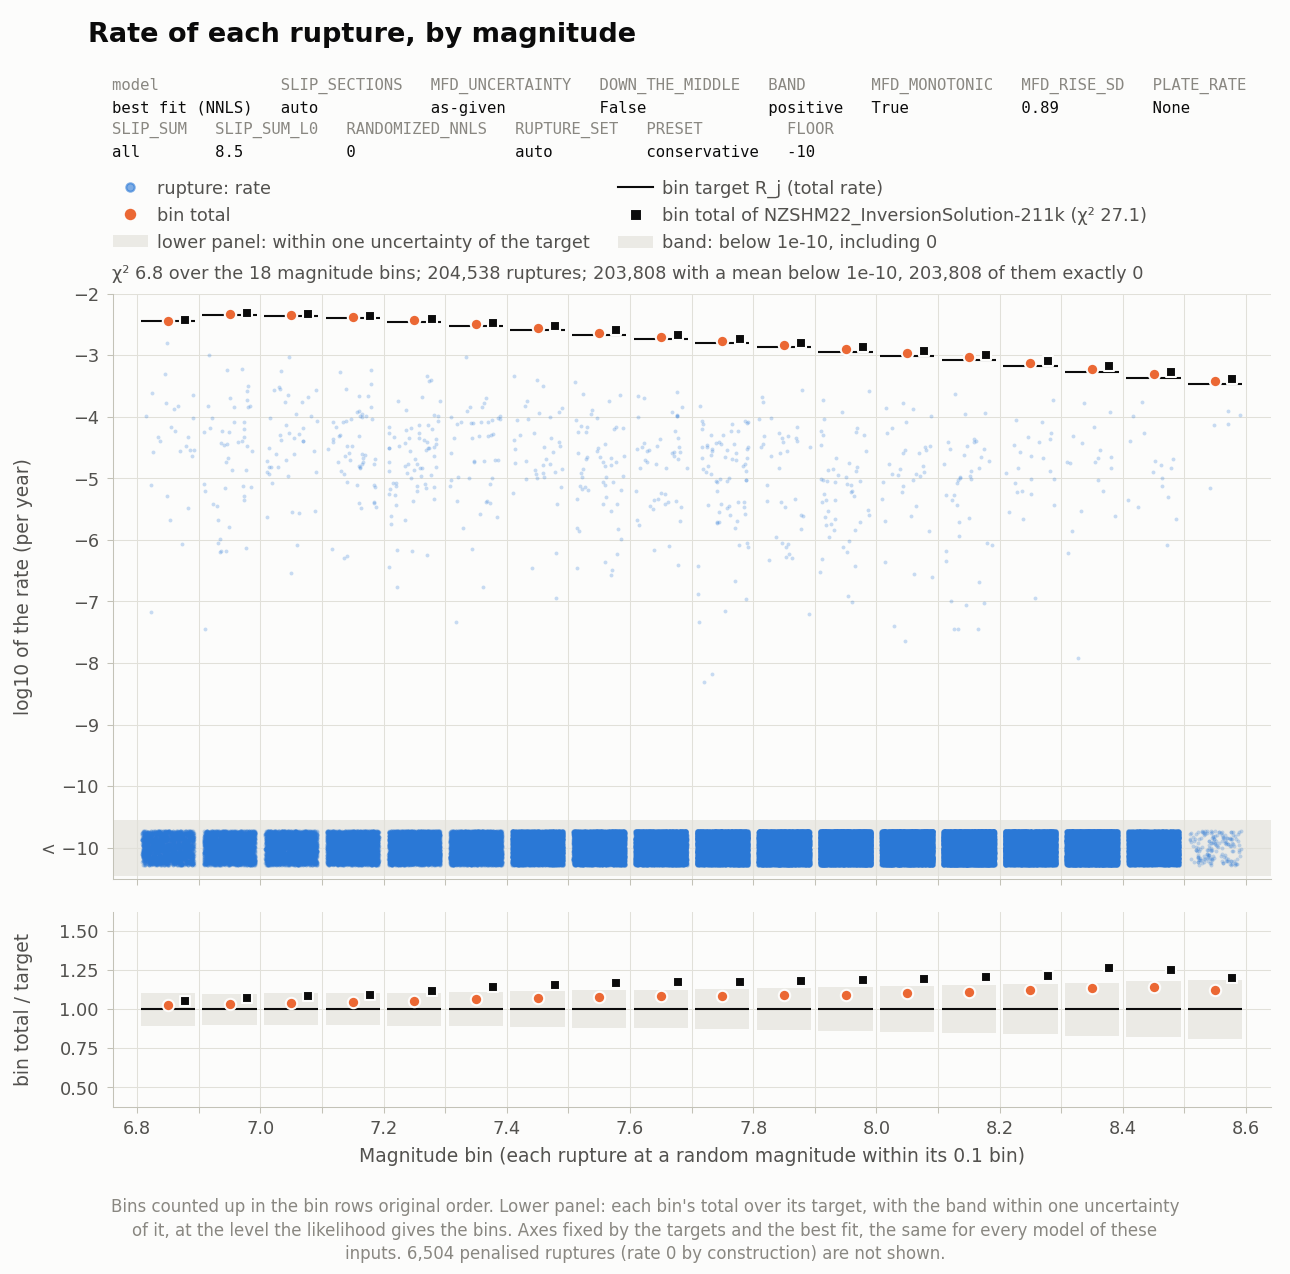

$ /Users/rollins/Library/CloudStorage/ProtonDrive-c.rollins@gns.cri.nz-folder/Inversions/Material/cru_workflow/tools/plot_paleo_rates.py nnls/nnls_vectors.npz:best fit (NNLS) --problem cru_clean.npz --out nnls/fig_paleo_rates_nnls.png --slip-block S --bins-block MFD --reference /Users/rollins/inversions/NZSHM22_Matrices-211k/NZSHM22_InversionSolution-211k/solution/rates.csv
paleo rows: 65 (the rows in neither 'S' nor 'MFD': row block 'B8:var'; original rows 8863-8927); targets from 1.35 to 10.7; targets and predictions in units of each row's uncertainty (a target is one over its relative uncertainty)
reference: NZSHM22_InversionSolution-211k (/Users/rollins/inversions/NZSHM22_Matrices-211k/NZSHM22_InversionSolution-211k/solution/rates.csv): its chi2 over the paleo rows 72.6; 65% of rows within one uncertainty of their targets, 91% within two; prediction / target: median 0.78 (5-95%: 0.31 to 1.09); its rates on the 298 ruptures cleaning removed (5.95e-05 per year, 0.14% of its total) ar

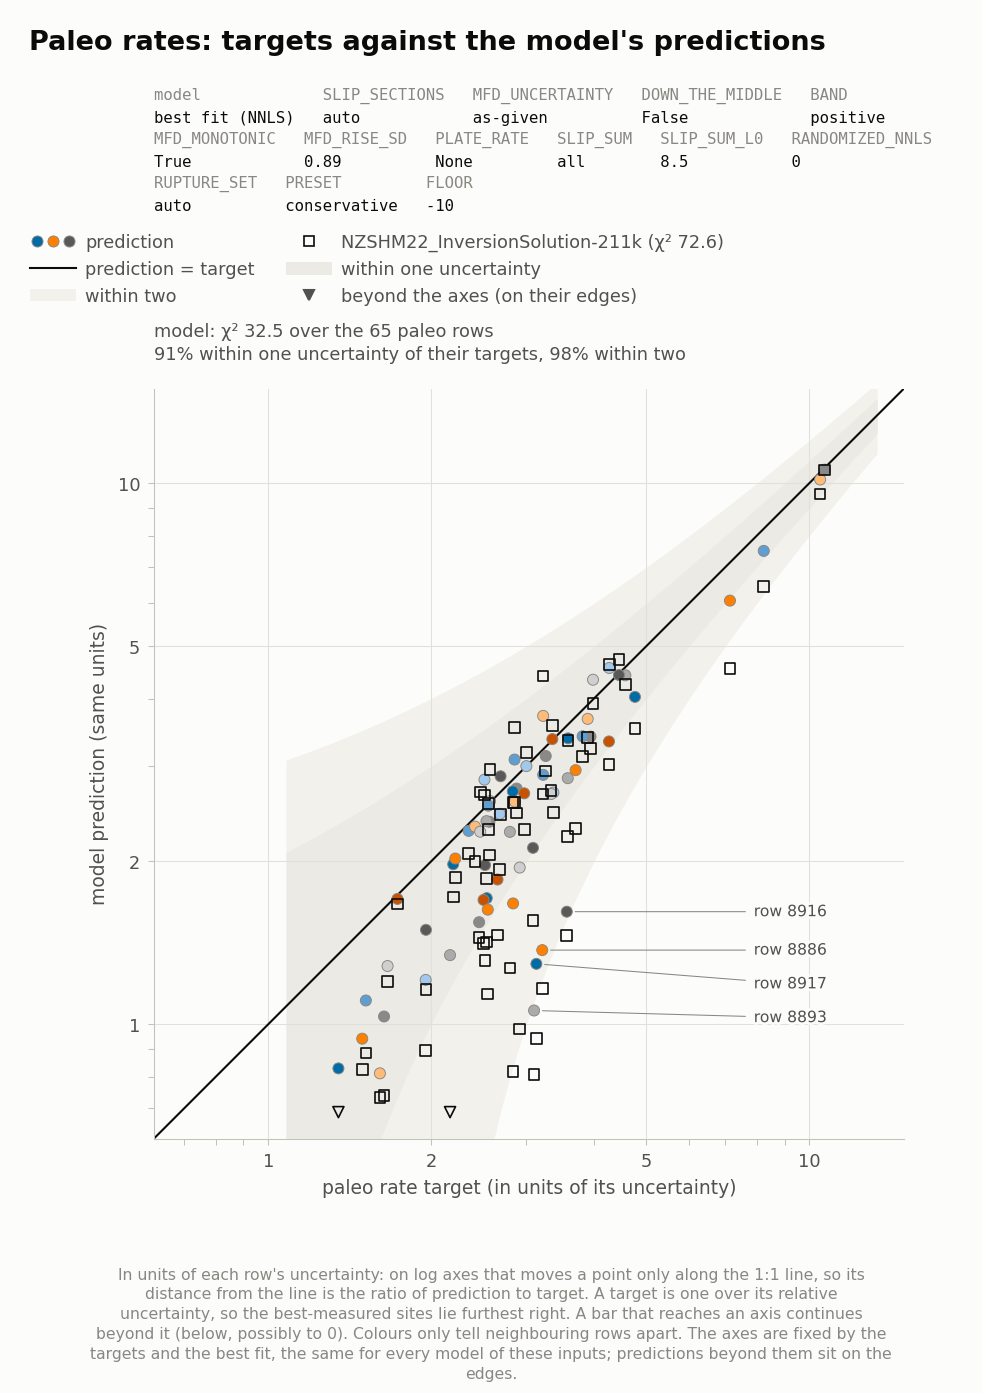

In [16]:
for _script, _fig, _more in (('plot_slip_rates.py', 'nnls/fig_slip_rates_nnls.png', []),     # the best fit's fit to the data
                             ('plot_rate_magnitude.py', 'nnls/fig_rate_magnitude_nnls.png', ['--bins-block', BIN_BLOCK, f'--diag-floor={FLOOR}']),
                             ('plot_paleo_rates.py', 'nnls/fig_paleo_rates_nnls.png', ['--bins-block', BIN_BLOCK])):
    sh(_script, 'nnls/nnls_vectors.npz:best fit (NNLS)', '--problem', 'cru_clean.npz', '--out', _fig, '--slip-block', SLIP_BLOCK,
       *_more, *ref_args())
    show(_fig)

**Rates for OpenSHA**: the best fit's (`nnls/rates.csv`) and the posterior mean's (`spikeslab/rates.csv`), each written by `make_solution.py` as an OpenSHA solution's `rates.csv`, with its report, `solution_report.txt`, beside it. Every rupture of the rupture set gets a rate, in its own numbering (the ruptures cleaning removed get 0), so each `rates.csv` has the same rows as the model's own OpenSHA solution's; `make_solution.py` first checks that the rupture set describes the same ruptures. The rupture set is looked for here, at the end, so a solution folder that appears in `DATA_DIR` during the run still serves; without one, nothing is written. From a terminal, `make_solution.py --zip` also writes a complete archive that OpenSHA loads.

In [17]:
_rd = rupture_dir()                                  # looked for now: a solution folder that appeared during the run serves
for _vec, _col, _out, _what in (('nnls/nnls_vectors.npz', [], 'nnls', 'the best fit'),
                                (os.path.join(results_dir(), 'rate_vectors.npz'), ['--column', 'mean'], results_dir(),
                                 'the posterior mean')):
    for _f in ('rates.csv', 'solution_report.txt', 'solution/rates.csv', 'solution/modules.json',
               'solution/sub_seismo_on_fault_mfds.csv'):   # an earlier run's (solution/: the layout before rates.csv)
        if os.path.exists(os.path.join(_out, _f)):     # would not match this one
            os.remove(os.path.join(_out, _f))
    if os.path.isdir(os.path.join(_out, 'solution')) and not os.listdir(os.path.join(_out, 'solution')):
        os.rmdir(os.path.join(_out, 'solution'))
    if not _rd:
        print(f'no OpenSHA rupture set (RUPTURE_SET): {_what} is not written as rates for OpenSHA')
    elif not os.path.exists(_vec):
        print(f'{_what} is not written as rates for OpenSHA: no rate vectors ({_vec})')
    else:                                            # a rate for every rupture of the rupture set, as in its own rates.csv
        sh('make_solution.py', _vec, *_col, '--ruptures', _rd, '--problem', 'cru_clean.npz', '--out', _out,
           '--slip-block', SLIP_BLOCK, '--bins-block', BIN_BLOCK)

$ /Users/rollins/Library/CloudStorage/ProtonDrive-c.rollins@gns.cri.nz-folder/Inversions/Material/cru_workflow/tools/make_solution.py nnls/nnls_vectors.npz --ruptures /Users/rollins/inversions/NZSHM22_Matrices-211k/NZSHM22_InversionSolution-211k/ruptures --problem cru_clean.npz --out nnls --slip-block S --bins-block MFD
== rates: nnls/nnls_vectors.npz, column mean: 211,042 ruptures, 730 nonzero, total 0.0394442/yr, largest 0.001567
== rupture set: /Users/rollins/inversions/NZSHM22_Matrices-211k/NZSHM22_InversionSolution-211k/ruptures: 211,042 ruptures, 8,333,787 section memberships
== checks against cru_clean.npz (204,538 ruptures kept, 6,504 removed, all at 0)
   sections: 204,538 of 204,538 kept ruptures have exactly the sections indices.csv lists (slip-rate row r = section r)
   magnitudes: 204,538 of 204,538 kept ruptures lie in their bin row's bin (6.80-8.60, 0.1 wide)
== wrote nnls/rates.csv
$ /Users/rollins/Library/CloudStorage/ProtonDrive-c.rollins@gns.cri.nz-folder/Inversions/

## 6. Open items

- A minority of ruptures that switch on and off mixes slowly: in quick runs at 211,000 ruptures about 200 (0.1%, carrying a fifth of the rate) with the swap moves, about 540 without them. Moves that pass the active role between ruptures that are not near-duplicates would help, and spike-and-slab's long run on the corrected inputs is still to do.
- The evidence of spike-and-slab, if wanted, from a few tempered runs by hand (the single-box evidence script is retired).
- An HMC cross-check of the current priors (the earlier log-space HMC script is set aside for now).
- Dispersed starts: chains started from simulated-annealing solutions or perturbed best fits (`gibbs.py --init`, from the command line), still the most important untested item.
- For the 5e5 configuration: filtered swap moves (cleaning already works on the sparse G throughout, and running summaries already allow runs without stored draws).
- Slip-rate sections are detected as runs of copies; the rupture set's subsection-to-section mapping (`SLIP_SECTIONS` as a file) would settle the sections whose target another section shares. Geodetic slip rates, which vary between subsections, are used as given; if their errors are correlated along a fault, they would need a covariance.
- The MFD bins' uncertainty level (`MFD_UNCERTAINTY`) is a modelling choice: `'as-given'` (the default) keeps the inputs' design value, each bin its own measurement; `'two-measurements'` counts the bins as the two measurements they come from, at the inputs' level and shape. A fuller treatment would give the bins a correlated covariance (the two measurements' uncertainty within a logic-tree branch, plus a model error per bin).
- Optional refinement: a similarity prior between overlapping ruptures.